# LC-AE: Autoencoder độ phức tạp thấp cho kênh CDL — SISO, SIMO 1×2, MIMO 2×2

**Mục tiêu.** Mở rộng notebook `P09_Autoencoder.ipynb` (autoencoder 64 điểm trên kênh AWGN) sang hệ OFDM với kênh 3GPP **CDL-C** và các kênh khác (CDL-A/B/D/E, CDL-C "stress"). Thuật toán đề xuất phải cho **BLER tốt hơn baseline** nhưng có **độ phức tạp thấp hơn**, đo bằng FLOPs, tham số, latency GPU/CPU, bộ nhớ GPU và chi phí huấn luyện.

**Ý tưởng.** Autoencoder gốc học chòm sao ở TX (bảng tra, gần như miễn phí khi chạy) và dùng một MLP 3→128→128→6 ở RX, tốn khoảng 35 kFLOP cho mỗi symbol. LC-AE giữ phần "học" ở những chỗ rẻ:

| Khối | P09 gốc / B1 | **LC-AE (đề xuất)** |
|---|---|---|
| TX | 64 điểm tự do (128 tham số) | **GS 2D đối xứng gương**: 16 điểm góc phần tư I, 32 tham số (LC-AE-2D) · **NUC tích 8-PAM×8-PAM**: 4 biên độ (LC-AE-1D) |
| Ước lượng kênh | LS + nearest-neighbour | **LR-LMMSE**: bộ lọc Wiener trong subspace thời gian × tần số hạng thấp, chỉ dùng pilot |
| Cân bằng | LMMSE | LMMSE (giống hệt, có tính sai số ước lượng) |
| Demapper | MLP 17.8 k tham số | **APP chính xác trên chòm sao đã học** + hiệu chỉnh LLR 2 tham số; bản 1D **tách được I/Q** (2 × 8 điểm) |

Toàn bộ được huấn luyện **end-to-end** bằng BCE như P09. Chòm sao được tối ưu **qua chính demapper rẻ** mà bộ thu sẽ dùng.

> **Kết quả chính** (chi tiết ở mục 12 — Tổng kết)
> * Trên 18 cặp (cấu hình anten, kênh), **LC-AE-2D cần ít hơn 2.0–3.4 dB Eb/N0 so với B0 (QAM + LS)** và **1.8–4.0 dB so với B1 (autoencoder P09)** tại BLER 1e-2. Nó bám sát Perfect CSI (−0.19…+0.12 dB).
> * Độ phức tạp so với B1: **÷15 FLOPs, ÷330 tham số**, thông lượng GPU/CPU nhanh hơn 1.2–2.2×, bộ nhớ GPU thấp hơn.
> * **LC-AE-1D**: ÷72–82 FLOPs, nhanh hơn 1.5–3.3×, bộ nhớ GPU ÷3.5. BLER chênh LC-AE-2D không quá 0.07 dB.
> * Hạn chế: cần thống kê kênh đúng (mô hình huấn luyện trên CDL-C hỏng trên kênh stress). Với GPU ở B = 1 slot, B1 nhỉnh hơn khoảng 0.04 ms.

## Mục lục
1. Thiết lập môi trường
2. Khối xây dựng chung: chòm sao, demapper, unit test
3. **Phần A — AWGN** (tái hiện P09 và so với LC-AE)
4. **Phần B — Hệ OFDM/CDL**: cấu hình, ước lượng kênh, cân bằng, unit test so với Sionna
5. Thống kê kênh: hạng hiệu dụng của từng kênh CDL
6. Công cụ huấn luyện và đánh giá (paired seeds)
7. Thí nghiệm: SISO 1×1 · SIMO 1×2 · MIMO 2×2 (mỗi kênh một mô hình chuyên biệt)
8. Kết quả BLER
9. Ablation và độ bền (CDL-C, stress)
10. Benchmark độ phức tạp
11. Trực quan: chòm sao đã học, đường học
12. Tổng kết

## 1. Thiết lập môi trường

* Mọi kết quả (weights, đường BLER, hình, bảng, log) được ghi vào thư mục `Claude outputs/` cạnh notebook.
* Các bước nặng (huấn luyện, mô phỏng BLER) được **cache ra đĩa**. Chạy lại notebook sẽ đọc kết quả đã có thay vì tính lại; xóa file tương ứng để tính lại.
* `P09C_SMOKE=1` chạy phiên bản thu nhỏ để kiểm tra code (không dùng cho kết quả).

In [1]:
%matplotlib inline
import os, sys, math, time, json, copy, pickle, platform, subprocess, threading, warnings, io, csv
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import psutil

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import sionna
from sionna.phy import config
from sionna.phy.channel import AWGN, GenerateOFDMChannel, ApplyOFDMChannel
from sionna.phy.channel.tr38901 import Antenna, AntennaArray, CDL
from sionna.phy.mimo import StreamManagement
from sionna.phy.ofdm import ResourceGrid, ResourceGridMapper, LSChannelEstimator, LMMSEEqualizer
from sionna.phy.utils import ebnodb2no
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder
from sionna.phy.mapping import Mapper, Demapper, Constellation, BinarySource

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
config.seed = 42
torch.manual_seed(42)

SMOKE = os.environ.get('P09C_SMOKE', '0') == '1'
OUT_DIR = Path(os.environ.get('P09C_OUT', 'Claude outputs'))
for _sub in ('weights', 'curves', 'stats', 'figures', 'logs'):
    (OUT_DIR / _sub).mkdir(parents=True, exist_ok=True)
P09_DIR = Path(os.environ.get('P09C_P09_DIR', '.'))     # original P09 weights/results live next to this notebook
LOG_FILE = OUT_DIR / 'logs' / 'run_log.txt'


def log(msg):
    line = f'[{time.strftime("%Y-%m-%d %H:%M:%S")}] {msg}'
    print(line, flush=True)
    with open(LOG_FILE, 'a', encoding='utf-8') as f:
        f.write(line + '\n')


def show_df(df):
    try:
        display(df)                      # IPython
    except NameError:
        print(df.to_string())


def fig_path(name):
    return OUT_DIR / 'figures' / f'claude_{name}.png'


HW = {
    'python': sys.version.split()[0], 'torch': torch.__version__, 'cuda': torch.version.cuda,
    'sionna': sionna.__version__, 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'cpu': platform.processor(), 'cpu_physical_cores': psutil.cpu_count(logical=False),
    'cpu_logical_cores': psutil.cpu_count(logical=True), 'torch_threads': torch.get_num_threads(),
    'os': platform.platform(), 'smoke_test': SMOKE,
}
for k_, v_ in HW.items():
    print(f'{k_:>18}: {v_}')
print(f'{"output folder":>18}: {OUT_DIR.resolve()}')
log(f'=== notebook start (smoke={SMOKE}) ===')

# Plot style. Categorical colours = validated reference palette; each system keeps a fixed slot everywhere.
# Line style + marker are the secondary encoding, so identity never relies on colour alone.
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#0b0b0b', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.titleweight': 'bold', 'legend.frameon': True,
                     'legend.framealpha': 0.95, 'lines.linewidth': 2.0, 'lines.markersize': 6,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
STYLE = {   # key: (label, colour, linestyle, marker)
    'perfect': ('Perfect CSI + QAM (cận dưới)',   '#0b0b0b', '-.', 'd'),
    'B0':      ('B0: QAM + LS + APP (baseline)',  '#e34948', '--', 's'),
    'B1':      ('B1: AE-P09 (MLP, LS)',           '#eb6834', '--', '^'),
    'B2':      ('B2: AE-FiLM (report, LS)',       '#eda100', ':',  'v'),
    'A1':      ('A1: QAM + LR-LMMSE + APP',       '#e87ba4', ':',  'x'),
    'A2':      ('A2: AE-MLP + LR-LMMSE',          '#4a3aa7', '-.', '+'),
    'LC2D':    ('LC-AE-2D (đề xuất)',             '#2a78d6', '-',  'o'),
    'LC1D':    ('LC-AE-1D (đề xuất)',             '#1baf7a', '-',  'P'),
    'LC2D-RL': ('LC-AE-2D, huấn luyện RL',        '#008300', '--', 'h'),
    'A2-APP':  ('A2-APP: TX + CE của A2, demapper APP', '#4a3aa7', ':', 'x'),
}
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#8a8983'

            python: 3.11.0
             torch: 2.5.1+cu121
              cuda: 12.1
            sionna: 2.0.1
               gpu: NVIDIA RTX A2000 12GB
               cpu: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
cpu_physical_cores: 24
 cpu_logical_cores: 32
     torch_threads: 24
                os: Windows-10-10.0.26200-SP0
        smoke_test: False
     output folder: E:\DungHuynh\Project\Sionna\Experts\P09_Autoencoder\Claude outputs
[2026-09-27 03:38:34] === notebook start (smoke=False) ===


### Quy mô thí nghiệm

| Tham số | Giá trị |
|---|---|
| Cấu hình anten | SISO 1×1, SIMO 1×2 (BS dual-pol), MIMO 2×2 (UT và BS dual-pol, 2 stream) |
| Kênh | CDL-A, B, C, D, E (DS 100 ns, 10 m/s) và CDL-C-stress (DS 300 ns, 30 m/s) |
| Huấn luyện | B1/A2/B2: 10 000 vòng × 32 slot, Adam 1e-3 (công thức P09) · LC-AE: 3 000 vòng × 32 slot, Adam 5e-3 → 5e-5 (cosine) · RL: 3 000 vòng xen kẽ + 500 vòng tinh chỉnh RX |
| Đánh giá | Paired seeds, 0.5 dB/bước, dừng ở ≥ 200 codeword lỗi hoặc 100 000 codeword; dừng quét khi BLER < 1e-3 hoặc khi gặp error floor (BLER giảm < 1.43× qua 4 bước liên tiếp; < 1.25× nếu waterfall thoải). Nếu waterfall thoải (rộng hơn 8 dB, ví dụ MIMO): bước 1 dB, tối đa 60 000 codeword/điểm, dừng tại BLER < 3e-3 |

In [2]:
NBPS = 6                               # 64-point constellations, as in P09
M_POINTS = 2 ** NBPS
CODERATE = 0.5
BIT_W = (2 ** torch.arange(NBPS - 1, -1, -1, device=device)).float()      # MSB first (Sionna convention)
LABELS = (torch.arange(M_POINTS, device=device)[:, None] >> torch.arange(NBPS - 1, -1, -1, device=device)) & 1

ANT_CONFIGS = ['1x1', '1x2', '2x2']
CHANNEL_KEYS = ['CDL-A', 'CDL-B', 'CDL-C', 'CDL-D', 'CDL-E', 'CDL-C-stress']
TRAIN_BATCH = 32                       # slots per SGD step (SISO: 44.5k symbols, comparable to P09's 128 x 250)
POOL_SIZE = 16384                      # pre-generated channel realisations used for training (eval: always fresh)
STATS_SAMPLES = 16384                  # channel realisations for the covariance statistics
RECIPES = {
    'B1':      dict(iters=10000, lr=1e-3, lr_final=None),          # verbatim P09 recipe (Adam, constant lr)
    'A2':      dict(iters=10000, lr=1e-3, lr_final=None),
    'B2':      dict(iters=10000, lr=1e-3, lr_final=None),
    'LC2D':    dict(iters=3000, lr=5e-3, lr_final=5e-5),
    'LC1D':    dict(iters=3000, lr=5e-3, lr_final=5e-5),
    'LC2D-RL': dict(alt=3000, ft=500, lr=5e-3, lr_final=5e-5, var=0.01),
}
EVAL = dict(batch=256, target_err=200, max_cw=100_000, stop_bler=1e-3, step=0.5,
            gentle_stop_bler=3e-3, gentle_max_cw=60_000)          # 'gentle' = waterfall wider than 8 dB (MIMO)
AWGN_CFG = dict(train_iters=3000, eval_batch=1024, target_err=1000, max_cw=128_000)
if SMOKE:
    ANT_CONFIGS, CHANNEL_KEYS = ['1x1', '2x2'], ['CDL-C', 'CDL-C-stress']
    POOL_SIZE, STATS_SAMPLES = 1024, 1024
    for _k in RECIPES:
        RECIPES[_k] = {**RECIPES[_k], 'iters': 40, 'alt': 20, 'ft': 10}
    EVAL = dict(batch=64, target_err=20, max_cw=2000, stop_bler=5e-2, step=1.0, gentle_stop_bler=5e-2,
                gentle_max_cw=2000)
    AWGN_CFG = dict(train_iters=40, eval_batch=256, target_err=50, max_cw=2048)
print('antenna configs:', ANT_CONFIGS, '| channels:', CHANNEL_KEYS)

antenna configs: ['1x1', '1x2', '2x2'] | channels: ['CDL-A', 'CDL-B', 'CDL-C', 'CDL-D', 'CDL-E', 'CDL-C-stress']


## 2. Khối xây dựng chung

### 2.1 Chòm sao (TX)

Quy ước nhãn bit của Sionna: chỉ số điểm $i$ ứng với 6 bit $b_0\dots b_5$ (MSB trước). Với 64-QAM Gray, phần thực phụ thuộc $(b_0,b_2,b_4)$, phần ảo phụ thuộc $(b_1,b_3,b_5)$, và $b_0$, $b_1$ là **bit dấu**.

* **Free-64 (B1, B2, A2):** đúng như P09. Có 128 tham số thực, khởi tạo bằng QAM, được đưa về tâm 0 và chuẩn hóa năng lượng.
* **SymGS-2D (LC-AE-2D):** chỉ học 16 điểm $q_r$ ở góc phần tư I. Điểm có nhãn $i$ là $x_i = s_I(b_0)\,\Re q_{r(i)} + j\,s_Q(b_1)\,\Im q_{r(i)}$, với $r(i)=i \bmod 16$. Chòm sao có tâm 0 và cân bằng giữa các góc phần tư ngay từ cấu trúc; số tham số giảm 4 lần. Khởi tạo trùng khít 64-QAM.
* **NUC-1D (LC-AE-1D):** $x = \mathrm{PAM}(b_0,b_2,b_4) + j\,\mathrm{PAM}(b_1,b_3,b_5)$ với một 8-PAM Gray **không đều** dùng chung cho I/Q. Chỉ có 4 biên độ học được. Vì chòm sao có dạng tích, APP demapper tách **chính xác** thành hai bài toán 8 điểm.

In [3]:
def normalize_points(p):
    p = p - p.mean()
    return p / p.abs().square().mean().sqrt()


def map_bits(c, points):
    """Bits [..., n] (MSB-first groups of NBPS) -> symbols [..., n/NBPS]; differentiable w.r.t. `points`."""
    idx = (c.reshape(*c.shape[:-1], -1, NBPS) * BIT_W).sum(-1).long()
    return points[idx]


_QAM = Constellation("qam", NBPS).points.to(device)                          # Sionna 64-QAM Gray, unit energy
_I_IDX = (LABELS[:, 0::2] * torch.tensor([4, 2, 1], device=device)).sum(-1)  # 8-PAM label of the real part
_Q_IDX = (LABELS[:, 1::2] * torch.tensor([4, 2, 1], device=device)).sum(-1)  # 8-PAM label of the imag part
_QAM_PAM = torch.zeros(8, device=device).index_put((_I_IDX,), _QAM.real)
assert torch.allclose(_QAM_PAM[_Q_IDX], _QAM.imag, atol=1e-6)
PAM_LABELS = (torch.arange(8, device=device)[:, None] >> torch.arange(2, -1, -1, device=device)) & 1   # [8,3]
_PAM_MAGS = torch.sort(_QAM_PAM[_QAM_PAM > 0]).values                        # 4 magnitudes, ascending
_PAM_LEVEL = (_QAM_PAM.abs()[:, None] - _PAM_MAGS[None]).abs().argmin(-1)     # magnitude index of each PAM label


class QAMConstellation(nn.Module):
    """Fixed 64-QAM Gray (Sionna) - used by B0, A1 and the perfect-CSI reference."""
    def __init__(self):
        super().__init__()
        self.register_buffer('_pts', _QAM.clone())
        self.register_buffer('_pam', _QAM_PAM.clone())

    def points(self):
        return self._pts

    def pam_levels(self):
        return self._pam


class FreeConstellation(nn.Module):
    """P09 transmitter: 64 free points (128 real parameters), initialised to 64-QAM, centred and
    normalised exactly like Constellation('custom', normalize=True, center=True)."""
    def __init__(self):
        super().__init__()
        self.points_r = nn.Parameter(_QAM.real.clone())
        self.points_i = nn.Parameter(_QAM.imag.clone())

    def points(self):
        return normalize_points(torch.complex(self.points_r, self.points_i))


class SymGSConstellation(nn.Module):
    """LC-AE-2D transmitter: 16 first-quadrant points mirrored by the sign bits b0 (I) and b1 (Q)."""
    def __init__(self):
        super().__init__()
        q1 = _QAM[:16]                                           # b0 = b1 = 0 -> first quadrant
        assert bool((q1.real > 0).all() and (q1.imag > 0).all())
        self.q_r = nn.Parameter(q1.real.clone())
        self.q_i = nn.Parameter(q1.imag.clone())
        self.register_buffer('_sI', 1 - 2 * LABELS[:, 0].float())
        self.register_buffer('_sQ', 1 - 2 * LABELS[:, 1].float())
        self.register_buffer('_r', torch.arange(M_POINTS, device=device) % 16)

    def points(self):
        p = torch.complex(self._sI * self.q_r[self._r], self._sQ * self.q_i[self._r])
        return p / p.abs().square().mean().sqrt()               # zero mean by construction


class NUC1DConstellation(nn.Module):
    """LC-AE-1D transmitter: product of two identical non-uniform Gray 8-PAMs (4 learnable amplitudes)."""
    def __init__(self):
        super().__init__()
        self.amp = nn.Parameter(_PAM_MAGS.clone())
        self.register_buffer('_sign', 1 - 2 * PAM_LABELS[:, 0].float())
        self.register_buffer('_level', _PAM_LEVEL.clone())
        self.register_buffer('_I', _I_IDX.clone())
        self.register_buffer('_Q', _Q_IDX.clone())

    def pam_levels(self):
        lv = self._sign * self.amp[self._level]
        return lv / (2 * lv.square().mean()).sqrt()             # E|x|^2 = 2 E[lv^2] = 1

    def points(self):
        lv = self.pam_levels()
        return torch.complex(lv[self._I], lv[self._Q])


class FrozenConstellation(nn.Module):
    """Inference-time look-up table: a learned constellation is a constant once training is over."""
    def __init__(self, tx):
        super().__init__()
        with torch.no_grad():
            self.register_buffer('_pts', tx.points().detach().clone())
            pam = tx.pam_levels() if hasattr(tx, 'pam_levels') else torch.zeros(8, device=self._pts.device)
            self.register_buffer('_pam', pam.detach().clone())

    def points(self):
        return self._pts

    def pam_levels(self):
        return self._pam

### 2.2 Demapper (RX)

* **`NeuralDemapperP09`**: giữ **nguyên văn** kiến trúc P09 (tên lớp con giống hệt để nạp được weights gốc). Input là $[\Re\hat x, \Im\hat x, \log_{10}N_{0,\mathrm{eff}}]$.
* **`FiLMDemapper`** (B2): theo `suggestion_report.md` (FiLM + SiLU + residual, hidden 128).
* **`APPDemapper2D`**: LLR chính xác $\mathrm{LLR}_i=\log\sum_{x\in\mathcal X_i^1}e^{-|y-x|^2/(\beta N_0)}-\log\sum_{x\in\mathcal X_i^0}e^{-|y-x|^2/(\beta N_0)}$ trên chòm sao **hiện tại** của TX. Hệ số hiệu chỉnh $\beta=\exp(w_0+w_1\log_{10}N_0)$ có 2 tham số, khởi tạo $\beta=1$, dùng để bù phần nhiễu không Gauss sau cân bằng.
* **`APPDemapper1D`**: với chòm sao dạng tích và nhiễu tròn, $p(y|x)=p(\Re y|\Re x)\,p(\Im y|\Im x)$, nên LLR của $(b_0,b_2,b_4)$ chỉ phụ thuộc $\Re y$ và 8 mức PAM. Kết quả **đúng bằng** APP-2D với khoảng 1/7 số FLOPs.

In [4]:
class NeuralDemapperP09(nn.Module):
    """Verbatim P09 demapper: [Re(y), Im(y), log10(N0)] -> 128 -> 128 -> 6, ReLU."""
    def __init__(self):
        super().__init__()
        self._dense_1 = nn.Linear(3, 128)
        self._dense_2 = nn.Linear(128, 128)
        self._dense_3 = nn.Linear(128, NBPS)

    def forward(self, y, no, const=None):
        z = torch.stack([y.real, y.imag, torch.log10(no).expand_as(y.real)], dim=-1)
        return self._dense_3(F.relu(self._dense_2(F.relu(self._dense_1(z)))))


class FiLMLayer(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.linear, self.gamma, self.beta = nn.Linear(d, d), nn.Linear(1, d), nn.Linear(1, d)

    def forward(self, h, no_db):
        return F.silu(self.linear(h) * self.gamma(no_db) + self.beta(no_db))


class FiLMDemapper(nn.Module):
    """B2 - 'AdvancedNeuralDemapper' of suggestion_report.md (FiLM, SiLU, residual, hidden 128)."""
    def __init__(self, d=128):
        super().__init__()
        self.in_proj, self.out_proj = nn.Linear(2, d), nn.Linear(d, NBPS)
        self.layer1, self.layer2 = FiLMLayer(d), FiLMLayer(d)

    def forward(self, y, no, const=None):
        no_db = torch.log10(no).expand_as(y.real).unsqueeze(-1)
        h = F.silu(self.in_proj(torch.stack([y.real, y.imag], dim=-1)))
        h = self.layer1(h, no_db) + h
        h = self.layer2(h, no_db) + h
        return self.out_proj(h)


class _Calibrated(nn.Module):
    """beta(N0) = exp(w0 + w1 log10 N0) scales the noise variance used by the analytic demapper."""
    def __init__(self, trainable):
        super().__init__()
        w = torch.zeros(2, device=device)
        if trainable:
            self.w = nn.Parameter(w)
        else:
            self.register_buffer('w', w)

    def inv_var(self, no):                  # 1 / (beta(N0) N0) = exp(-w0 - (1 + w1 / ln10) ln N0)
        return torch.exp(-(self.w[0] + (1.0 + self.w[1] / math.log(10.0)) * torch.log(no)))


def _lse_diff(e, M):
    """log sum_{bit=1} exp(e) - log sum_{bit=0} exp(e) for all bits at once: one exp pass and ONE matmul with the
    0/1 label mask M = [M1 | M0]. The max-shift cancels exactly in the difference (so it is detached).
    Exponents are clipped at -80 (exp(-80) ~ 1.8e-35 is still a normal float32; much lower arguments hit a ~60x
    slower exp path on x86 CPUs). |LLR| therefore saturates at ~80, far beyond the LDPC decoder's clipping (20)."""
    p = torch.exp((e - e.max(-1, keepdim=True).values.detach()).clamp_min(-80.0))
    lg = torch.log((p @ M).clamp_min(1e-37))
    k = M.shape[-1] // 2
    return lg[..., :k] - lg[..., k:]


class APPDemapper2D(_Calibrated):
    """Exact APP LLRs on the current constellation. The exponents -s|y-p|^2 of all 64 points are produced by ONE
    GEMM with K = 4:  [2s Re y, 2s Im y, -s, -s|y|^2] @ [Re p; Im p; |p|^2; 1]."""
    def __init__(self, trainable=True):
        super().__init__(trainable)
        self.register_buffer('M', torch.cat([LABELS.float(), 1.0 - LABELS.float()], 1))       # [64,12]

    def forward(self, y, no, const):
        pts = const.points()
        s = self.inv_var(no)
        ya = torch.stack([2 * s * y.real, 2 * s * y.imag, -s, -s * y.abs().square()], -1)     # [..., 4]
        pa = torch.stack([pts.real, pts.imag, pts.abs().square(), torch.ones_like(pts.real)])  # [4, 64]
        return _lse_diff(ya @ pa, self.M)                                                     # [..., 6]


class APPDemapper1D(_Calibrated):
    def __init__(self, trainable=True):
        super().__init__(trainable)
        self.register_buffer('M', torch.cat([PAM_LABELS.float(), 1.0 - PAM_LABELS.float()], 1))   # [8,6]

    def forward(self, y, no, const):
        lv = const.pam_levels()                                                    # [8]
        s = self.inv_var(no).unsqueeze(-1)                                         # [..., 1]
        yr = torch.stack([y.real, y.imag], dim=-1)                                 # [..., 2]
        ya = torch.stack([2 * s * yr, -s.expand_as(yr), -s * yr.square()], -1)     # [..., 2, 3]
        la = torch.stack([lv, lv.square(), torch.ones_like(lv)])                   # [3, 8]
        llr = _lse_diff(ya @ la, self.M)                                           # [..., 2(I/Q), 3]
        return llr.transpose(-1, -2).flatten(-2)                                   # -> b0,b1,b2,b3,b4,b5


def count_trainable(m):
    return int(sum(p.numel() for p in m.parameters() if p.requires_grad))

### 2.3 Unit test: khối tự viết khớp Sionna

In [5]:
with torch.no_grad():
    for _cls in (FreeConstellation, SymGSConstellation, NUC1DConstellation):
        assert torch.allclose(_cls().points(), _QAM, atol=1e-6), _cls.__name__
    config.seed = 3
    _c = BinarySource()([4, 600])
    assert torch.allclose(map_bits(_c, _QAM), Mapper("qam", NBPS)(_c), atol=1e-6)
    _rand_pts = normalize_points(torch.randn(64, dtype=torch.complex64, device=device))
    _map_custom = Mapper(constellation=Constellation("custom", NBPS, points=_rand_pts))
    assert torch.allclose(map_bits(_c, _rand_pts), _map_custom(_c), atol=1e-5)
    _y = torch.randn(4, 100, dtype=torch.complex64, device=device)
    _no = torch.rand(4, 100, device=device) * 0.3 + 0.01
    _ref = Demapper("app", "qam", NBPS)(_y, _no)
    _q = QAMConstellation()
    _l2 = APPDemapper2D(False)(_y, _no, _q).reshape(4, -1)
    _l1 = APPDemapper1D(False)(_y, _no, _q).reshape(4, -1)
    _rel = lambda a, b: float(((a.clamp(-50, 50) - b.clamp(-50, 50)).abs() / (1 + b.clamp(-50, 50).abs())).max())
    print(f'APP-2D vs Sionna Demapper("app"): max rel. diff = {_rel(_l2, _ref):.2e}')
    print(f'APP-1D vs Sionna Demapper("app"): max rel. diff = {_rel(_l1, _ref):.2e}')
    assert _rel(_l2, _ref) < 1e-4 and _rel(_l1, _ref) < 1e-4
print('Parameters  | Free-64:', count_trainable(FreeConstellation()), '| SymGS-2D:', count_trainable(SymGSConstellation()),
      '| NUC-1D:', count_trainable(NUC1DConstellation()))
print('            | MLP-P09:', count_trainable(NeuralDemapperP09()), '| FiLM:', count_trainable(FiLMDemapper()),
      '| APP-2D/1D (calibration):', count_trainable(APPDemapper2D()))
print('All building-block unit tests passed.')

APP-2D vs Sionna Demapper("app"): max rel. diff = 6.95e-06
APP-1D vs Sionna Demapper("app"): max rel. diff = 2.45e-06
Parameters  | Free-64: 128 | SymGS-2D: 32 | NUC-1D: 4
            | MLP-P09: 17798 | FiLM: 35206 | APP-2D/1D (calibration): 2
All building-block unit tests passed.


## 3. Phần A — AWGN: tái hiện P09 và so với LC-AE

Cấu hình **giống hệt P09**: n = 1500, k = 750, LDPC 5G, Eb/N0 ∈ [4, 8] dB, batch 128.

* **QAM (baseline P09):** 64-QAM Gray + APP.
* **AE-conv / AE-RL (P09):** **nạp weights gốc** `awgn_autoencoder_weights_*`, không huấn luyện lại.
* **LC-AE-2D / LC-AE-1D:** huấn luyện 3 000 vòng. Đây là số vòng ít hơn 10 000 vòng của P09, vì LC-AE chỉ có 34 và 6 tham số.

Đường BLER lưu trong file `awgn_autoencoder_results` của P09 được vẽ chồng lên (nét mảnh) để kiểm tra việc tái hiện.

In [6]:
N_AWGN, K_AWGN = 1500, 750


def _ebno_vec(B, ebno):
    ebno = torch.as_tensor(ebno, dtype=torch.float32, device=device)
    return ebno.expand(B) if ebno.dim() == 0 else ebno


class AWGNLink(nn.Module):
    """P09 link: bits -> constellation -> AWGN -> demapper -> (LDPC)."""
    def __init__(self, tx, demapper):
        super().__init__()
        self.tx, self.demapper = tx, demapper
        for name, obj in [('_src', BinarySource()), ('_awgn', AWGN())]:
            object.__setattr__(self, name, obj)
        enc = LDPC5GEncoder(K_AWGN, N_AWGN, NBPS)
        object.__setattr__(self, '_enc', enc)
        object.__setattr__(self, '_dec', LDPC5GDecoder(enc, hard_out=True))

    def _llr(self, c, B, ebno):
        no = ebnodb2no(_ebno_vec(B, ebno), NBPS, CODERATE)[:, None]              # [B,1]
        y = self._awgn(map_bits(c, self.tx.points()), no)
        return self.demapper(y, no.expand_as(y.real), self.tx).reshape(B, -1)

    def bce(self, B, ebno):
        c = self._src([B, N_AWGN])
        return F.binary_cross_entropy_with_logits(self._llr(c, B, ebno), c)

    def forward(self, B, ebno):
        b = self._src([B, K_AWGN])
        return b, self._dec(self._llr(self._enc(b), B, ebno))


def load_p09_awgn(fname):
    sd = torch.load(P09_DIR / fname, map_location=device, weights_only=True)
    link = AWGNLink(FreeConstellation(), NeuralDemapperP09()).to(device)
    link.load_state_dict({('tx.' + k if k.startswith('points_') else k.replace('_demapper.', 'demapper.')): v
                          for k, v in sd.items()})
    return link.eval()

### 3.1 Công cụ chung: huấn luyện và mô phỏng BLER (dùng cho cả phần A và B)

* **Huấn luyện:** mỗi mẫu trong batch lấy Eb/N0 riêng, phân bố đều trên dải huấn luyện (như P09). Loss là BCE, tương đương tối đa hóa BMD rate $=1-\mathrm{BCE}/\ln 2$.
* **Đánh giá (paired seeds):** tại mỗi Eb/N0 đặt `config.seed = base + round(100·Eb/N0)`. Mọi hệ thống trong cùng một cấu hình/kênh thấy **đúng cùng** bit, kênh và nhiễu, nên chênh lệch BLER phản ánh thuật toán chứ không phải may rủi Monte-Carlo.

In [7]:
def sample_ebno(B, rng):
    return torch.empty(B, device=device).uniform_(*rng)


@torch.no_grad()
def bmd_rate(link, ebnos, nb=4, batch=64, seed=90210):
    """Bit-metric decoding rate 1 - BCE/ln2 [bit/bit] at fixed seeds."""
    out = []
    for j, eb in enumerate(ebnos):
        config.seed = seed + j
        out.append(float(1 - np.mean([link.bce(batch, float(eb)).item() for _ in range(nb)]) / math.log(2)))
    return out


def train_conventional(link, iters, lr, rng, lr_final=None, batch=TRAIN_BATCH, seed=0, label='', val_ebnos=None,
                       n_val=8):
    params = [p for p in link.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters, eta_min=lr_final) if lr_final else None
    hist = {'it': [], 'loss': [], 'val_it': [], 'val': []}
    val_every = max(iters // n_val, 1)
    config.seed = seed
    link.train()
    t0, ema = time.perf_counter(), None
    for i in range(iters):
        loss = link.bce(batch, sample_ebno(batch, rng))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        if sched is not None:
            sched.step()
        if i % 25 == 0 or i == iters - 1:
            lv = loss.item()
            ema = lv if ema is None else 0.8 * ema + 0.2 * lv
            hist['it'].append(i); hist['loss'].append(ema)
        if val_ebnos is not None and ((i + 1) % val_every == 0 or i == iters - 1):
            link.eval()
            hist['val_it'].append(i + 1); hist['val'].append(bmd_rate(link, val_ebnos))
            config.seed = seed + i + 1
            link.train()
        if i % 250 == 0:
            print(f'\r  {label} it {i:5d}/{iters}  BCE(ema) {ema:.4f}  {time.perf_counter() - t0:6.0f}s', end='', flush=True)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    print(f'\r  {label} done: {iters} it x B={batch} in {dt / 60:.1f} min ({1e3 * dt / iters:.1f} ms/it), '
          f'final BCE(ema) {ema:.4f}' + (f', val BMD {hist["val"][-1]}' if hist['val'] else '') + ' ' * 10, flush=True)
    link.eval()
    info = dict(iters=iters, batch=batch, time_s=dt, ms_per_iter=1e3 * dt / iters, trainable=count_trainable(link),
                lr=lr, lr_final=lr_final, rng=list(rng))
    return hist, info


@torch.no_grad()
def simulate_bler(link, grid, batch, target_err=200, max_cw=150_000, stop_bler=1e-3, seed_base=10_000, label='',
                  floor_guard=True, floor_ratio=0.7):
    keys = ['ebno', 'ber', 'bler', 'blk_err', 'blocks', 'bit_err', 'bits', 'time']
    res = {k: [] for k in keys}
    print(f'--- {label} ---')
    for eb in grid:
        config.seed = seed_base + int(round(float(eb) * 100))
        be = bb = nbits = nblk = 0
        t0 = time.perf_counter()
        while bb < target_err and nblk < max_cw:
            b, b_hat = link(batch, float(eb))
            err = b != b_hat
            be += int(err.sum()); bb += int(err.any(-1).sum()); nbits += err.numel(); nblk += err[..., 0].numel()
        dt = time.perf_counter() - t0
        for k, v in zip(keys, [float(eb), be / nbits, bb / nblk, bb, nblk, be, nbits, dt]):
            res[k].append(v)
        print(f'  {eb:6.2f} dB | BER {be / nbits:9.3e} | BLER {bb / nblk:9.3e} | {bb:5d}/{nblk:7d} | {dt:5.1f}s', flush=True)
        if bb == 0 or bb / nblk < stop_bler:
            break
        bl = res['bler']
        if floor_guard and len(bl) >= 5 and bl[-1] < 0.05 and bl[-1] > floor_ratio * bl[-5]:
            print(f'  (error floor: < {1 / floor_ratio:.2f}x BLER improvement over the last 4 steps -> stop)')
            break
    return {k: np.array(v) for k, v in res.items()}


def snr_at_bler(curve, target):
    e, b = np.asarray(curve['ebno']), np.asarray(curve['bler'])
    for i in range(len(b) - 1):
        if b[i] >= target > b[i + 1]:
            if b[i + 1] <= 0:
                return float(e[i + 1])
            y0, y1 = np.log10(b[i]), np.log10(b[i + 1])
            return float(e[i] + (np.log10(target) - y0) * (e[i + 1] - e[i]) / (y1 - y0))
    return float('nan')


def wilson_ci(errors, n_, z=1.96):
    errors, n_ = np.asarray(errors, float), np.asarray(n_, float)
    p = errors / n_
    den = 1 + z ** 2 / n_
    ctr = (p + z ** 2 / (2 * n_)) / den
    hw = z * np.sqrt(p * (1 - p) / n_ + z ** 2 / (4 * n_ ** 2)) / den
    return np.maximum(ctr - hw, 1e-12), ctr + hw


def cached_pickle(path, fn):
    path = Path(path)
    if path.exists():
        with open(path, 'rb') as f:
            return pickle.load(f)
    res = fn()
    with open(path, 'wb') as f:
        pickle.dump(res, f)
    return res

### 3.2 Huấn luyện LC-AE trên AWGN và đánh giá

In [8]:
AWGN_RANGE = (4.0, 8.0)                    # P09 training / evaluation range
AWGN_GRID = np.arange(4.0, 8.01, 0.5) if not SMOKE else np.arange(4.0, 8.01, 1.0)
AWGN_LINKS = {}                            # name -> link
AWGN_TRAIN = {}

AWGN_LINKS['QAM'] = AWGNLink(QAMConstellation(), APPDemapper2D(False)).to(device).eval()
AWGN_LINKS['AE-conv'] = load_p09_awgn('awgn_autoencoder_weights_conventional_training')
AWGN_LINKS['AE-RL'] = load_p09_awgn('awgn_autoencoder_weights_rl_training')

for name, tx_cls, dm_cls in [('LC2D', SymGSConstellation, APPDemapper2D), ('LC1D', NUC1DConstellation, APPDemapper1D)]:
    link = AWGNLink(tx_cls(), dm_cls(True)).to(device)
    wp = OUT_DIR / 'weights' / f'claude_awgn_{name}.pt'
    if wp.exists():
        ck = torch.load(wp, map_location=device, weights_only=True)
        link.load_state_dict(ck['state_dict']); AWGN_TRAIN[name] = ck['log']
        print(f'{name}: loaded {wp.name}')
    else:
        hist, info = train_conventional(link, AWGN_CFG['train_iters'], 5e-3, AWGN_RANGE, lr_final=5e-5, batch=128,
                                        seed=11, label=f'AWGN {name}', val_ebnos=[5.5, 6.5])
        AWGN_TRAIN[name] = {'hist': hist, 'info': info}
        torch.save({'state_dict': link.state_dict(), 'log': AWGN_TRAIN[name]}, wp)
    AWGN_LINKS[name] = link.eval()

AWGN_CURVES = {}
for name, link in AWGN_LINKS.items():
    AWGN_CURVES[name] = cached_pickle(
        OUT_DIR / 'curves' / f'claude_awgn_{name}.pkl',
        lambda: simulate_bler(link, AWGN_GRID, AWGN_CFG['eval_batch'], AWGN_CFG['target_err'], AWGN_CFG['max_cw'],
                              stop_bler=0.0, seed_base=20_000, label=f'AWGN {name}', floor_guard=False))
log('AWGN part done')

LC2D: loaded claude_awgn_LC2D.pt
LC1D: loaded claude_awgn_LC1D.pt
[2026-09-27 03:38:34] AWGN part done


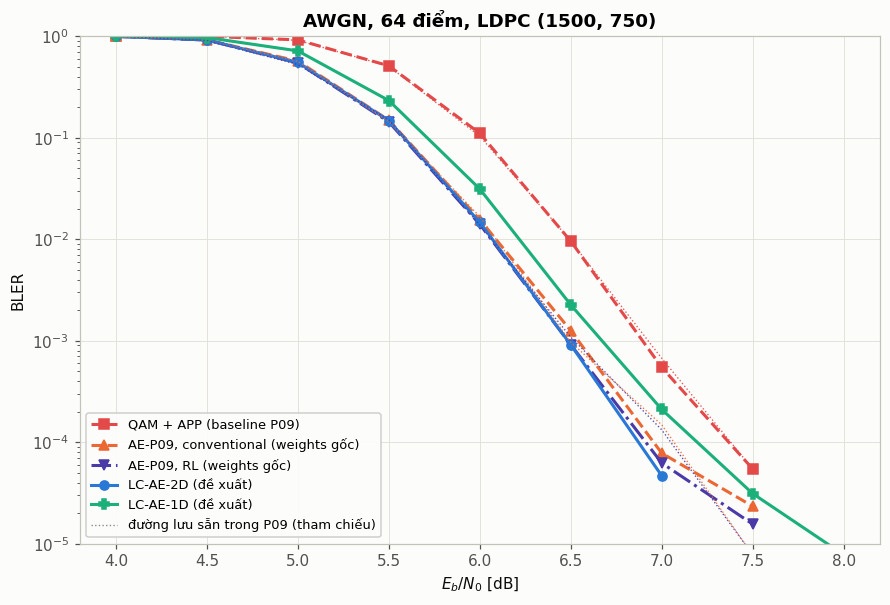

,trainable params (TX+RX),Eb/N0 @ BLER 1e-02,Eb/N0 @ BLER 1e-03,Eb/N0 @ BLER 1e-04
system,,,,
QAM + APP (baseline P09),0,6.491,6.895,7.369
"AE-P09, conventional (weights gốc)",17926,6.088,6.541,6.956
"AE-P09, RL (weights gốc)",17926,6.062,6.484,6.912
LC-AE-2D (đề xuất),34,6.069,6.484,6.872
LC-AE-1D (đề xuất),6,6.217,6.672,7.195


In [9]:
with open(P09_DIR / 'awgn_autoencoder_results', 'rb') as f:
    _p09_ebno, _p09_bler = pickle.load(f)
AWGN_STYLE = {'QAM': ('QAM + APP (baseline P09)', STYLE['B0'][1], '--', 's'),
              'AE-conv': ('AE-P09, conventional (weights gốc)', STYLE['B1'][1], '--', '^'),
              'AE-RL': ('AE-P09, RL (weights gốc)', STYLE['A2'][1], '-.', 'v'),
              'LC2D': ('LC-AE-2D (đề xuất)', STYLE['LC2D'][1], '-', 'o'),
              'LC1D': ('LC-AE-1D (đề xuất)', STYLE['LC1D'][1], '-', 'P')}
fig, ax = plt.subplots(figsize=(8.2, 5.6))
for name, (lab, col, ls, mk) in AWGN_STYLE.items():
    c_ = AWGN_CURVES[name]
    m = c_['bler'] > 0
    ax.semilogy(c_['ebno'][m], c_['bler'][m], color=col, ls=ls, marker=mk, label=lab)
for key, name in [('baseline', 'QAM'), ('autoencoder-conv', 'AE-conv'), ('autoencoder-rl', 'AE-RL')]:
    ax.semilogy(_p09_ebno, _p09_bler[key], color=AWGN_STYLE[name][1], lw=0.9, ls=':', alpha=0.9)
ax.plot([], [], color=MUTED, lw=0.9, ls=':', label='đường lưu sẵn trong P09 (tham chiếu)')
ax.set_xlabel(r'$E_b/N_0$ [dB]'); ax.set_ylabel('BLER'); ax.set_ylim(1e-5, 1.0)
ax.set_title('AWGN, 64 điểm, LDPC (1500, 750)')
ax.legend(loc='lower left', fontsize=8.5)
fig.tight_layout(); fig.savefig(fig_path('awgn_bler'), dpi=150); plt.show()

AWGN_TH = []
for name in AWGN_STYLE:
    row = {'system': AWGN_STYLE[name][0], 'trainable params (TX+RX)': count_trainable(AWGN_LINKS[name]) if name.startswith('LC')
           else (0 if name == 'QAM' else 128 + count_trainable(NeuralDemapperP09()))}
    for t in (1e-2, 1e-3, 1e-4):
        row[f'Eb/N0 @ BLER {t:.0e}'] = snr_at_bler(AWGN_CURVES[name], t)
    AWGN_TH.append(row)
AWGN_TH = pd.DataFrame(AWGN_TH).set_index('system')
show_df(AWGN_TH.round(3))

## 4. Phần B — Hệ OFDM/CDL

### 4.1 Cấu hình

Lưới OFDM **giống P05**: 3.5 GHz, SCS 30 kHz, FFT 128 (116 subcarrier hữu dụng), 14 symbol, pilot Kronecker ở symbol 2 và 11, không CP, uplink, `normalize_channel=True`. Mỗi stream có 1 392 RE dữ liệu.

**Mã hóa:** LDPC 5G (n = 1392, k = 696, rate 1/2), **6 codeword cho mỗi stream mỗi slot**. Độ dài codeword gần với n = 1500 của P09. Mỗi codeword chiếm trọn 2 symbol OFDM trên toàn băng, nên vẫn hưởng frequency diversity như một codeword dài cả slot. Codeword ngắn giúp đánh giá BLER nhanh hơn khoảng 10× (decode n = 8352 tốn 3.1 ms/codeword trên RTX A2000).

| Cấu hình | UT (phát) | BS (thu) | Stream | Pilot mỗi stream |
|---|---|---|---|---|
| SISO 1×1 | 1 anten V | 1 anten V | 1 | 232 (mọi SC ở symbol 2, 11) |
| SIMO 1×2 | 1 anten V | 1 phần tử dual-pol V/H | 1 | 232 |
| MIMO 2×2 | dual-pol V/H | dual-pol V/H | 2 (spatial multiplexing) | 116 (SC xen kẽ, trực giao) |

In [10]:
FC = 3.5e9
SETUP_SPECS = {'1x1': (1, 1), '1x2': (1, 2), '2x2': (2, 2)}     # (UT antennas = streams, BS antennas)
CW_PER_STREAM, N_OFDM, K_OFDM = 6, 1392, 696
CHANNELS = {
    'CDL-A': dict(model='A', ds=100e-9, speed=10.0),
    'CDL-B': dict(model='B', ds=100e-9, speed=10.0),
    'CDL-C': dict(model='C', ds=100e-9, speed=10.0),
    'CDL-D': dict(model='D', ds=100e-9, speed=10.0),
    'CDL-E': dict(model='E', ds=100e-9, speed=10.0),
    'CDL-C-stress': dict(model='C', ds=300e-9, speed=30.0),
}


def make_array(num_ant):
    if num_ant == 1:
        return Antenna(polarization="single", polarization_type="V", antenna_pattern="38.901", carrier_frequency=FC)
    return AntennaArray(num_rows=1, num_cols=1, polarization="dual", polarization_type="VH",
                        antenna_pattern="38.901", carrier_frequency=FC)


class OFDMSetup:
    """Resource grid, stream management, LDPC and all index bookkeeping of one antenna configuration."""
    def __init__(self, key):
        self.key = key
        self.S, self.nrx = SETUP_SPECS[key]
        self.L = self.S * self.nrx                                   # number of links, l = a * S + s
        config.seed = 42                                             # Kronecker pilots come from Sionna's RNG
        self.rg = ResourceGrid(num_ofdm_symbols=14, fft_size=128, subcarrier_spacing=30e3, num_tx=1,
                               num_streams_per_tx=self.S, cyclic_prefix_length=0, dc_null=True,
                               pilot_pattern="kronecker", pilot_ofdm_symbol_indices=[2, 11],
                               num_guard_carriers=[5, 6])
        self.sm = StreamManagement(np.array([[1]]), self.S)
        self.rgm, self.apply = ResourceGridMapper(self.rg), ApplyOFDMChannel()
        self.ut_array, self.bs_array = make_array(self.S), make_array(self.nrx)
        self.T, self.Fq, self.Nd = 14, int(self.rg.num_effective_subcarriers), int(self.rg.num_data_symbols)
        self.n_slot = self.Nd * NBPS
        assert self.n_slot == CW_PER_STREAM * N_OFDM
        self.enc = LDPC5GEncoder(K_OFDM, N_OFDM, NBPS)
        self.dec = LDPC5GDecoder(self.enc, hard_out=True)
        self.sc_ind = torch.as_tensor(np.asarray(self.rg.effective_subcarrier_ind), device=device).long()
        self.pilot_syms = [2, 11]
        self.data_syms = [t for t in range(self.T) if t not in self.pilot_syms]
        self.data_syms_t = torch.tensor(self.data_syms, device=device)
        mask = self.rg.pilot_pattern.mask[0].bool()                  # [S,14,116]
        for s in range(self.S):                                      # Kronecker: pilot symbols are fully reserved
            for t in range(self.T):
                assert bool(mask[s, t].all()) == bool(mask[s, t].any()) == (t in self.pilot_syms)
        pil = self.rg.pilot_pattern.pilots[0].reshape(self.S, 2, self.Fq)
        self.pilot_sc, self.pilot_val = [], []
        for s in range(self.S):
            nz = pil[s, 0].abs() > 0
            assert torch.equal(nz, pil[s, 1].abs() > 0)
            self.pilot_sc.append(torch.nonzero(nz).flatten())         # active pilot subcarriers of stream s
            self.pilot_val.append(pil[s][:, nz].clone())              # [2, F_s]
        self.pilot_pow = [float(v.abs().square().mean()) for v in self.pilot_val]
        self.Fs = len(self.pilot_sc[0])


def make_gen(su, spec):
    cdl = CDL(spec['model'], spec['ds'], FC, su.ut_array, su.bs_array, 'uplink',
              min_speed=spec['speed'], max_speed=spec['speed'])
    return GenerateOFDMChannel(cdl, su.rg, normalize_channel=True)


SETUPS = {k: OFDMSetup(k) for k in ANT_CONFIGS}
for k, su in SETUPS.items():
    print(f'{k}: S={su.S}, nrx={su.nrx}, data REs/stream={su.Nd}, active pilots/stream={2 * su.Fs}, '
          f'|p|^2={su.pilot_pow}, codewords/slot={su.S * CW_PER_STREAM}')

1x1: S=1, nrx=1, data REs/stream=1392, active pilots/stream=232, |p|^2=[1.0], codewords/slot=6
1x2: S=1, nrx=2, data REs/stream=1392, active pilots/stream=232, |p|^2=[1.0], codewords/slot=6
2x2: S=2, nrx=2, data REs/stream=1392, active pilots/stream=116, |p|^2=[1.9999998807907104, 1.9999998807907104], codewords/slot=12


### 4.2 Ước lượng kênh

**LS + nearest-neighbour (B0, B1, B2).** Đây là `LSChannelEstimator(interpolation_type="nn")` của Sionna, viết lại dưới dạng phép *gather* thuần PyTorch. Bảng nearest-neighbour được **trích từ chính Sionna**, và unit test ở 4.4 xác nhận output trùng khớp. Viết lại như vậy giúp mọi bộ thu chạy được trên cả CPU lẫn GPU khi benchmark.

**LR-LMMSE (A1, A2, LC-AE).** Mỗi link $\ell=(a,s)$ được mô hình hóa theo dạng tách được, hạng thấp:
$$h_\ell[t,f]=\sum_{i=1}^{r_t}\sum_{j=1}^{r_f}U_{t,\ell}[t,i]\,U_{f,\ell}[f,j]\,c_\ell[i,j]+e_\ell[t,f],\qquad c_\ell\sim\mathcal{CN}(0,\mathrm{diag}(\lambda_\ell)),\ e_\ell\sim\mathcal{CN}(0,\varepsilon_\ell).$$
$U_t, U_f$ là vector riêng của hiệp phương sai thời gian và tần số, ước lượng từ 16 384 realization kênh. $\lambda,\varepsilon$ được khởi tạo từ thống kê, sau đó **fine-tune end-to-end** (LC-AE, A2) hoặc giữ cố định (A1). Với pilot LS $z=\Phi c+w$ và $\sigma^2=N_0/|p|^2+\varepsilon$:
$$\hat c=\big(\Phi^H\Phi/\sigma^2+\Lambda^{-1}\big)^{-1}\Phi^H z/\sigma^2 = W\,\mathrm{diag}\!\Big(\tfrac{1}{d_k/\sigma^2+1}\Big)W^H\,\Phi^H z/\sigma^2,$$
với $W=\Lambda^{1/2}V$ và $\Lambda^{1/2}\Phi^H\Phi\Lambda^{1/2}=VDV^H$.

* **Khi suy luận:** $W, d, q$ là hằng số tính sẵn, nên mỗi slot chỉ cần vài phép nhân ma trận–vector cỡ $R=r_tr_f$, cộng thêm một "co ngót" phụ thuộc SNR. Không cần nghịch đảo ma trận.
* **Khi huấn luyện:** dùng Cholesky, ổn định gradient theo $\lambda$.
* Phương sai sai số trung bình trên RE dữ liệu $\mathrm{tr}(A^{-1}M_d)+\varepsilon$ được đưa vào bộ cân bằng LMMSE, như `err_var` của Sionna.

In [11]:
@torch.no_grad()
def derive_nn_map(su):
    """Nearest-neighbour table of Sionna's LS estimator: data RE -> index of the active pilot used."""
    est = LSChannelEstimator(su.rg, interpolation_type="nn")
    y = torch.zeros(1, 1, su.nrx, su.T, 128, dtype=torch.complex64, device=device)
    for s in range(su.S):
        codes = torch.arange(1, 2 * su.Fs + 1, device=device).reshape(2, su.Fs).to(torch.complex64)
        for ti, t in enumerate(su.pilot_syms):
            y[0, 0, :, t, su.sc_ind[su.pilot_sc[s]]] = su.pilot_val[s][ti] * codes[ti]
    h, _ = est(y, torch.tensor(1.0, device=device))                         # [1,1,nrx,1,S,14,116]
    hd = h[0, 0, 0, 0][:, su.data_syms].reshape(su.S, -1)                    # [S, Nd]
    assert float(hd.imag.abs().max()) < 1e-3
    nn_map = hd.real.round().long() - 1
    assert int(nn_map.min()) >= 0 and int(nn_map.max()) < 2 * su.Fs
    return nn_map


class LSnnEstimator(nn.Module):
    def __init__(self, su):
        super().__init__()
        self.S, self.nrx = su.S, su.nrx
        self.register_buffer('psym', torch.tensor(su.pilot_syms, device=device))
        self.register_buffer('psc', torch.stack(su.pilot_sc))                               # [S,F_s]
        self.register_buffer('pinv', torch.stack([v.conj() / v.abs().square() for v in su.pilot_val]))   # [S,2,F_s]
        self.register_buffer('nn_map', derive_nn_map(su))                                   # [S,Nd]
        self.register_buffer('ppow', torch.tensor(su.pilot_pow, device=device))

    def forward(self, y, no):                                   # y [B,nrx,14,116], no [B]
        yp = y[:, :, self.psym]                                 # [B,nrx,2,116]
        hs = []
        for s in range(self.S):
            z = yp[..., self.psc[s]] * self.pinv[s]             # [B,nrx,2,F_s]  LS at the active pilots
            hs.append(z.flatten(-2)[..., self.nn_map[s]])       # [B,nrx,Nd]    nearest-neighbour
        err = (no[:, None, None] / self.ppow).expand(-1, self.nrx, -1)                   # [B,nrx,S]
        return torch.stack(hs, 2), err


def _bkron(a, b):
    """Batched Kronecker product [L,m,m] x [L,n,n] -> [L,mn,mn]."""
    L_, m, n = a.shape[0], a.shape[-1], b.shape[-1]
    return (a[:, :, None, :, None] * b[:, None, :, None, :]).reshape(L_, m * n, m * n)


class LRLMMSEEstimator(nn.Module):
    """Pilot-only low-rank separable LMMSE ('eigen-domain Wiener filter')."""
    def __init__(self, su, stats, trainable=True):
        super().__init__()
        self.S, self.nrx, self.L, self.Nd = su.S, su.nrx, su.L, su.Nd
        self.rt, self.rf = stats['rt'], stats['rf']
        self.R = self.rt * self.rf
        Ut, Uf = stats['Ut'].to(device), stats['Uf'].to(device)              # [L,14,rt], [L,116,rf]
        stream = [l % self.S for l in range(self.L)]
        Ut_p, Ut_d = Ut[:, su.pilot_syms], Ut[:, su.data_syms]
        Uf_p = torch.stack([Uf[l][su.pilot_sc[stream[l]]] for l in range(self.L)])        # [L,F_s,rf]
        self.Fs = su.Fs
        self.register_buffer('UtpcT', Ut_p.conj().transpose(-1, -2).contiguous())               # [L,rt,2]
        self.register_buffer('Uf_pc', Uf_p.conj().contiguous())                                  # [L,F_s,rf]
        self.register_buffer('Ut_d', Ut_d.contiguous())                                          # [L,12,rt]
        self.register_buffer('UfT', Uf.transpose(-1, -2).contiguous())                           # [L,rf,116]
        # flat index of every link's active pilots in y.reshape(B, nrx*14*116) and the matching 1/p
        a_idx = [l // self.S for l in range(self.L)]
        psym_t = torch.tensor(su.pilot_syms, device=device)[:, None]
        self.register_buffer('pidx', torch.stack([((a_idx[l] * su.T + psym_t) * su.Fq + su.pilot_sc[stream[l]][None]).reshape(-1)
                                                  for l in range(self.L)]))                       # [L,2F_s]
        self.register_buffer('pinv', torch.stack([(su.pilot_val[s].conj() / su.pilot_val[s].abs().square()).reshape(-1)
                                                  for s in stream]))                              # [L,2F_s]
        self.register_buffer('ppow', torch.tensor([su.pilot_pow[s] for s in stream], device=device))
        self.register_buffer('G', _bkron(Ut_p.mH @ Ut_p, Uf_p.mH @ Uf_p))                    # Phi^H Phi   [L,R,R]
        self.register_buffer('Md', _bkron(Ut_d.mH @ Ut_d, Uf.mH @ Uf) / su.Nd)               # data-RE Gram / Nd
        log_lam = torch.log(stats['lam'].to(device).clamp_min(1e-10))
        log_eps = torch.log(stats['eps'].to(device).clamp_min(1e-9))
        if trainable:
            self.log_lam, self.log_eps = nn.Parameter(log_lam), nn.Parameter(log_eps)
        else:
            self.register_buffer('log_lam', log_lam)
            self.register_buffer('log_eps', log_eps)
        for name in ('_Wc', '_Wt', '_dv', '_q'):
            self.register_buffer(name, None, persistent=False)
        self.frozen = False

    @torch.no_grad()
    def freeze(self):
        """Pre-compute the eigen-domain filter (inference constants)."""
        sq = torch.exp(0.5 * self.log_lam).to(self.G.dtype)
        K = sq[:, :, None] * self.G * sq[:, None, :]
        dv, V = torch.linalg.eigh(0.5 * (K + K.mH))
        W = sq[:, :, None] * V
        self._Wc, self._Wt, self._dv = W.conj().contiguous(), W.transpose(-1, -2).contiguous(), dv.clamp_min(0)
        self._q = torch.diagonal(W.mH @ self.Md @ W, dim1=-2, dim2=-1).real
        self.frozen = True

    def unfreeze(self):
        self.frozen = False

    def forward(self, y, no):                                    # y [B,nrx,14,116], no [B]
        B = y.shape[0]
        z = (y.reshape(B, -1)[:, self.pidx] * self.pinv).view(B, self.L, 2, self.Fs)             # LS at pilots
        b = (self.UtpcT @ (z @ self.Uf_pc)).reshape(B, self.L, self.R)                           # Phi^H z
        eps = torch.exp(self.log_eps)
        sig2 = no[:, None] / self.ppow + eps                                                     # [B,L]
        if self.frozen:                                           # eigen-domain Wiener filter: 2 small mat-vecs
            shrink = 1.0 / (self._dv / sig2[..., None] + 1.0)                                    # [B,L,R]
            u = (b.unsqueeze(-2) @ self._Wc) * (shrink / sig2[..., None]).unsqueeze(-2)          # W^H b, scaled
            c = (u @ self._Wt).squeeze(-2)                                                       # W u
            err = (self._q * shrink).sum(-1) + eps
        else:
            A = self.G / sig2[..., None, None].to(self.G.dtype) + torch.diag_embed(torch.exp(-self.log_lam)).to(self.G.dtype)
            Lc = torch.linalg.cholesky(A)
            rhs = torch.cat([(b / sig2[..., None]).unsqueeze(-1), self.Md.expand(B, -1, -1, -1)], -1)
            sol = torch.cholesky_solve(rhs, Lc)
            c = sol[..., 0]
            err = torch.diagonal(sol[..., 1:], dim1=-2, dim2=-1).sum(-1).real + eps
        H = self.Ut_d @ (c.reshape(B, self.L, self.rt, self.rf) @ self.UfT)                       # [B,L,12,116]
        return H.reshape(B, self.nrx, self.S, self.Nd), err.reshape(B, self.nrx, self.S)

### 4.3 Cân bằng LMMSE, bộ thu và liên kết end-to-end

`lmmse_equalize` thực hiện **đúng công thức** của `sionna.phy.ofdm.LMMSEEqualizer` (không có nhiễu từ TX khác):
* Nhiễu cộng với sai số ước lượng kênh cho mỗi anten thu là $N_0+\sum_s\sigma^2_{e,a,s}$.
* Làm trắng (whitening), rồi tính $\hat x=\mathrm{diag}(GH)^{-1}Gy$ với $G=(H^HH+I)^{-1}H^H$.
* $N_{0,\mathrm{eff}}=1/\mathrm{diag}(GH)-1$.

Nghịch đảo được viết dạng đóng cho 1 và 2 stream.

In [12]:
def lmmse_equalize(yd, hd, err, no):
    """yd [B,nrx,Nd], hd [B,nrx,S,Nd], err [B,nrx,S] (CSI error variance per link), no [B]
    -> x_hat [B,S,Nd], no_eff [B,S,Nd]   (identical to Sionna's LMMSEEqualizer, whiten_interference=True)."""
    s_ = no[:, None] + err.sum(-1)                               # [B,nrx]
    w = s_.rsqrt().unsqueeze(-1)                                 # [B,nrx,1]
    yt, ht = yd * w, hd * w.unsqueeze(2)
    S = hd.shape[2]
    if S == 1:
        h0 = ht[:, :, 0]
        g = h0.abs().square().sum(1)                             # [B,Nd]
        x = (h0.conj() * yt).sum(1) / g
        return x[:, None], (1.0 / g)[:, None]
    assert S == 2
    h0, h1 = ht[:, :, 0], ht[:, :, 1]
    a = 1 + h0.abs().square().sum(1)
    c = 1 + h1.abs().square().sum(1)
    bq = (h0.conj() * h1).sum(1)
    r0, r1 = (h0.conj() * yt).sum(1), (h1.conj() * yt).sum(1)
    det = a * c - bq.abs().square()
    u0, u1 = (c * r0 - bq * r1) / det, (a * r1 - bq.conj() * r0) / det
    d0, d1 = 1 - c / det, 1 - a / det
    return torch.stack([u0 / d0, u1 / d1], 1), torch.stack([1 / d0 - 1, 1 / d1 - 1], 1)


class Receiver(nn.Module):
    """y [B,nrx,14,128] -> LLR [B,S,Nd,6]. ce=None means perfect CSI (true channel h is used)."""
    def __init__(self, su, ce, demapper):
        super().__init__()
        self.S, self.nrx = su.S, su.nrx
        self.register_buffer('sc_ind', su.sc_ind.clone())
        self.register_buffer('data_syms', su.data_syms_t.clone())
        self.ce, self.demapper = ce, demapper

    def forward(self, y, no, h=None, const=None):
        yf = y[..., self.sc_ind]                                             # [B,nrx,14,116]
        yd = yf[:, :, self.data_syms].flatten(-2)                            # [B,nrx,Nd]
        if self.ce is None:
            hd = h[:, 0, :, 0][..., self.sc_ind][..., self.data_syms, :].flatten(-2)
            err = torch.zeros(y.shape[0], self.nrx, self.S, device=y.device)
        else:
            hd, err = self.ce(yf, no)
        x_hat, no_eff = lmmse_equalize(yd, hd, err, no)
        return self.demapper(x_hat, no_eff, const)


class OFDMLink(nn.Module):
    """bits -> (LDPC) -> constellation -> RG mapper -> CDL (GenerateOFDMChannel) + AWGN -> Receiver -> (LDPC)."""
    def __init__(self, su, chan, tx, ce, demapper):
        super().__init__()
        object.__setattr__(self, 'su', su)
        object.__setattr__(self, '_chan', chan)
        object.__setattr__(self, '_src', BinarySource())
        self.tx = tx
        self.rx = Receiver(su, ce, demapper)

    def set_channel(self, chan):
        object.__setattr__(self, '_chan', chan)

    def transmit(self, B, ebno, coded, perturb_var=0.0):
        no = ebnodb2no(_ebno_vec(B, ebno), NBPS, CODERATE, self.su.rg)                   # [B]
        S = self.su.S
        if coded:
            b = self._src([B, S, CW_PER_STREAM, K_OFDM])
            c = self.su.enc(b).reshape(B, S, -1)
        else:
            b, c = None, self._src([B, S, self.su.n_slot])
        x = map_bits(c, self.tx.points())                                                # [B,S,Nd]
        x_p = x
        if perturb_var > 0:
            std = math.sqrt(0.5 * perturb_var)
            x_p = x + torch.complex(torch.randn_like(x.real), torch.randn_like(x.real)) * std
        h = self._chan(B)                                                                # [B,1,nrx,1,S,14,128]
        y = self.su.apply(self.su.rgm(x_p.unsqueeze(1)), h, no.view(-1, 1, 1, 1, 1))[:, 0]   # [B,nrx,14,128]
        return b, c, x, x_p, y, h, no

    def bce(self, B, ebno):
        _, c, _, _, y, h, no = self.transmit(B, ebno, coded=False)
        return F.binary_cross_entropy_with_logits(self.rx(y, no, h, self.tx).flatten(-2), c)

    def rl_losses(self, B, ebno, var):
        """P09 RL training: the channel is a black box (y detached); the TX gradient is the REINFORCE surrogate.
        The RX knows the constellation, so the demapper term d(BCE)/d(points) | y fixed is also available."""
        _, c, x, x_p, y, h, no = self.transmit(B, ebno, coded=False, perturb_var=var)
        llr = self.rx(y.detach(), no, h, self.tx)                                         # [B,S,Nd,6]
        bce = F.binary_cross_entropy_with_logits(llr, c.reshape(llr.shape), reduction='none').mean(-1)
        tx_loss = None
        if var > 0:
            p = x_p.detach() - x
            tx_loss = (-bce.detach() * p.abs().square() / var).mean()
        return tx_loss, bce.mean()

    def forward(self, B, ebno):
        b, _, _, _, y, h, no = self.transmit(B, ebno, coded=True)
        llr = self.rx(y, no, h, self.tx).reshape(B, self.su.S, CW_PER_STREAM, N_OFDM)
        return b, self.su.dec(llr)

### 4.4 Unit test: khớp với pipeline Sionna gốc

Với mỗi cấu hình anten, ta so sánh:
1. Ánh xạ RE dữ liệu và pilot so với `ResourceGridMapper`.
2. LS-nn tự viết so với `LSChannelEstimator("nn")`.
3. `lmmse_equalize` so với `LMMSEEqualizer`.
4. **Toàn bộ chuỗi thu B0** (LS → LMMSE → APP) so với chuỗi Sionna `LSChannelEstimator` → `LMMSEEqualizer` → `Demapper("app")`, so trên LLR.
5. LR-LMMSE: nhánh huấn luyện (Cholesky) và nhánh suy luận (eigen) cho cùng kết quả.
6. Paired seeds: hai hệ thống khác nhau thấy cùng bit và cùng kênh.

In [13]:
def _rel(a, b):
    if not torch.is_complex(a):
        a, b = a.clamp(-50, 50), b.clamp(-50, 50)
    return float(((a - b).abs() / (1 + b.abs())).max())


@torch.no_grad()
def unit_tests_ofdm(su):
    gen = make_gen(su, CHANNELS['CDL-C'])
    B = 8
    # 1. data / pilot RE bookkeeping
    config.seed = 5
    x = map_bits(BinarySource()([B, su.S, su.n_slot]), _QAM)
    xg = su.rgm(x.unsqueeze(1))[:, 0][..., su.sc_ind]                                   # [B,S,14,116]
    assert torch.allclose(xg[:, :, su.data_syms].flatten(-2), x)
    for s in range(su.S):
        assert torch.allclose(xg[0, s, su.pilot_syms][:, su.pilot_sc[s]], su.pilot_val[s])
    # 2-4. B0 chain vs Sionna blocks, on a real CDL-C realisation
    no = ebnodb2no(torch.full([B], 12.0, device=device), NBPS, CODERATE, su.rg)
    h = gen(B)
    y = su.apply(su.rgm(x.unsqueeze(1)), h, no.view(-1, 1, 1, 1, 1))
    ls_ref = LSChannelEstimator(su.rg, interpolation_type="nn")
    h_ref, ev_ref = ls_ref(y, no)                                                         # [B,1,nrx,1,S,14,116]
    ls_mine = LSnnEstimator(su)
    yf = y[:, 0][..., su.sc_ind]
    h_m, ev_m = ls_mine(yf, no)
    h_ref_d = h_ref[:, 0, :, 0][..., su.data_syms, :].flatten(-2)
    ev_ref_d = ev_ref.expand_as(h_ref)[:, 0, :, 0][..., su.data_syms, :].flatten(-2)
    d_ls = _rel(h_m, h_ref_d); d_ev = _rel(ev_m[..., None].expand_as(ev_ref_d), ev_ref_d)
    eq_ref = LMMSEEqualizer(su.rg, su.sm)
    xh_ref, noe_ref = eq_ref(y, h_ref, ev_ref, no)                                        # [B,1,S,Nd]
    xh_m, noe_m = lmmse_equalize(yf[:, :, su.data_syms].flatten(-2), h_m, ev_m, no)
    d_x, d_n = _rel(xh_m, xh_ref[:, 0]), _rel(noe_m, noe_ref[:, 0])
    llr_ref = Demapper("app", "qam", NBPS)(xh_ref, noe_ref)[:, 0]                         # [B,S,Nd*6]
    rx_b0 = Receiver(su, ls_mine, APPDemapper2D(False))
    llr_m = rx_b0(y[:, 0], no, None, QAMConstellation()).flatten(-2)
    d_llr = _rel(llr_m, llr_ref)
    print(f'[{su.key}] LS-nn h {d_ls:.1e} | err_var {d_ev:.1e} | LMMSE x_hat {d_x:.1e} | no_eff {d_n:.1e} | '
          f'full B0 chain LLR {d_llr:.1e}')
    assert max(d_ls, d_ev, d_x, d_n) < 1e-4 and d_llr < 1e-3
    # 5. LR-LMMSE: Cholesky (training) == eigen-domain (inference)
    st = channel_statistics(su, gen, num=1024, batch=512)
    lr = LRLMMSEEstimator(su, st)
    ha, ea = lr(yf, no)
    lr.freeze()
    hb, eb_ = lr(yf, no)
    h_true = h[:, 0, :, 0][..., su.sc_ind][..., su.data_syms, :].flatten(-2)
    nmse_lr = float((ha - h_true).abs().square().mean() / h_true.abs().square().mean())
    nmse_ls = float((h_m - h_true).abs().square().mean() / h_true.abs().square().mean())
    print(f'[{su.key}] LR-LMMSE chol vs eigen: h {_rel(ha, hb):.1e}, err {_rel(ea, eb_):.1e} | '
          f'NMSE @12 dB: LS {10 * math.log10(nmse_ls):.1f} dB, LR {10 * math.log10(nmse_lr):.1f} dB '
          f'(predicted {10 * math.log10(float(ea.mean() / h_true.abs().square().mean())):.1f} dB)')
    assert _rel(ha, hb) < 1e-3 and _rel(ea, eb_) < 1e-3
    # 6. paired seeds
    l1 = OFDMLink(su, gen, QAMConstellation(), LSnnEstimator(su), APPDemapper2D(False))
    l2 = OFDMLink(su, gen, SymGSConstellation(), None, APPDemapper2D(False))
    config.seed = 99; r1 = l1.transmit(4, 10.0, True)
    config.seed = 99; r2 = l2.transmit(4, 10.0, True)
    assert torch.equal(r1[0], r2[0]) and torch.equal(r1[5], r2[5])

## 5. Thống kê kênh: hạng hiệu dụng

Với mỗi cấu hình và mỗi kênh, ta ước lượng hiệp phương sai theo tần số $R_f$ (116×116) và theo thời gian $R_t$ (14×14) cho từng link, dùng 16 384 realization. Hạng được chọn là số mode nhỏ nhất chứa ≥ 99.99 % năng lượng (trung bình trên các link), với $r_f\le 32$ và $r_t\le 2$. Chỉ có 2 symbol pilot, nên mode thời gian thứ 3 trở đi không quan sát được.

In [14]:
@torch.no_grad()
def channel_statistics(su, gen, num=STATS_SAMPLES, batch=512, seed=7, energy=1 - 1e-4, rf_max=32, rt_max=2):
    L, T, Fq = su.L, su.T, su.Fq
    nb = max(num // batch, 1)

    def draw():
        return gen(batch)[:, 0, :, 0][..., su.sc_ind].reshape(batch, L, T, Fq).to(torch.complex128)

    config.seed = seed
    Rf = torch.zeros(L, Fq, Fq, dtype=torch.complex128, device=device)
    Rt = torch.zeros(L, T, T, dtype=torch.complex128, device=device)
    pw = torch.zeros(L, dtype=torch.float64, device=device)
    for _ in range(nb):
        h = draw()
        Rf += torch.einsum('bltf,bltg->lfg', h, h.conj())
        Rt += torch.einsum('bltf,blsf->lts', h, h.conj())
        pw += h.abs().square().mean((2, 3)).sum(0)
    Rf /= nb * batch * T; Rt /= nb * batch * Fq; pw /= nb * batch
    mu_f, Vf = torch.linalg.eigh(Rf); mu_f, Vf = mu_f.flip(-1).clamp_min(0), Vf.flip(-1)
    mu_t, Vt = torch.linalg.eigh(Rt); mu_t, Vt = mu_t.flip(-1).clamp_min(0), Vt.flip(-1)
    sf = (mu_f / mu_f.sum(-1, keepdim=True)).mean(0).cumsum(0)
    st = (mu_t / mu_t.sum(-1, keepdim=True)).mean(0).cumsum(0)
    rf = int(min(max(int((sf < energy).sum()) + 1, 2), rf_max))
    rt = int(min(max(int((st < energy).sum()) + 1, 1), rt_max))
    Uf, Ut = Vf[..., :rf], Vt[..., :rt]
    config.seed = seed                                   # second pass, same realisations: coefficient variances
    lam = torch.zeros(L, rt, rf, dtype=torch.float64, device=device)
    for _ in range(nb):
        c = torch.einsum('lti,bltf,lfj->blij', Ut.conj(), draw(), Uf.conj())
        lam += c.abs().square().sum(0)
    lam /= nb * batch
    eps = (pw * T * Fq - lam.sum((1, 2))).clamp_min(1e-6 * pw * T * Fq) / (T * Fq)
    return dict(Ut=Ut.to(torch.complex64), Uf=Uf.to(torch.complex64), lam=lam.reshape(L, -1).float(),
                eps=eps.float(), rt=rt, rf=rf, pow=pw.float().cpu(),
                mu_f=(mu_f / mu_f.sum(-1, keepdim=True)).float().cpu(), mu_t=(mu_t / mu_t.sum(-1, keepdim=True)).float().cpu(),
                captured=float(1 - (eps * T * Fq / (pw * T * Fq)).mean()))


for su in SETUPS.values():
    unit_tests_ofdm(su)
print('All OFDM unit tests passed.')

[1x1] LS-nn h 1.7e-07 | err_var 0.0e+00 | LMMSE x_hat 2.9e-07 | no_eff 2.8e-07 | full B0 chain LLR 1.5e-05


[1x1] LR-LMMSE chol vs eigen: h 2.0e-07, err 5.8e-11 | NMSE @12 dB: LS -15.8 dB, LR -34.1 dB (predicted -34.6 dB)
[1x2] LS-nn h 1.7e-07 | err_var 0.0e+00 | LMMSE x_hat 3.2e-07 | no_eff 3.3e-07 | full B0 chain LLR 2.6e-05


[1x2] LR-LMMSE chol vs eigen: h 2.9e-07, err 5.8e-11 | NMSE @12 dB: LS -15.9 dB, LR -34.6 dB (predicted -34.9 dB)


[2x2] LS-nn h 1.3e-07 | err_var 0.0e+00 | LMMSE x_hat 2.5e-05 | no_eff 2.2e-05 | full B0 chain LLR 6.4e-05


[2x2] LR-LMMSE chol vs eigen: h 3.2e-07, err 2.9e-11 | NMSE @12 dB: LS -21.5 dB, LR -37.6 dB (predicted -37.8 dB)
All OFDM unit tests passed.


Channel statistics for 18 (config, channel) pairs: 0.0 s
config        1x1  1x2  2x2
channel                    
CDL-A           4    4    4
CDL-B           6    6    6
CDL-C           4    4    4
CDL-D           8   10   10
CDL-E           8    8    8
CDL-C-stress    6    6    6


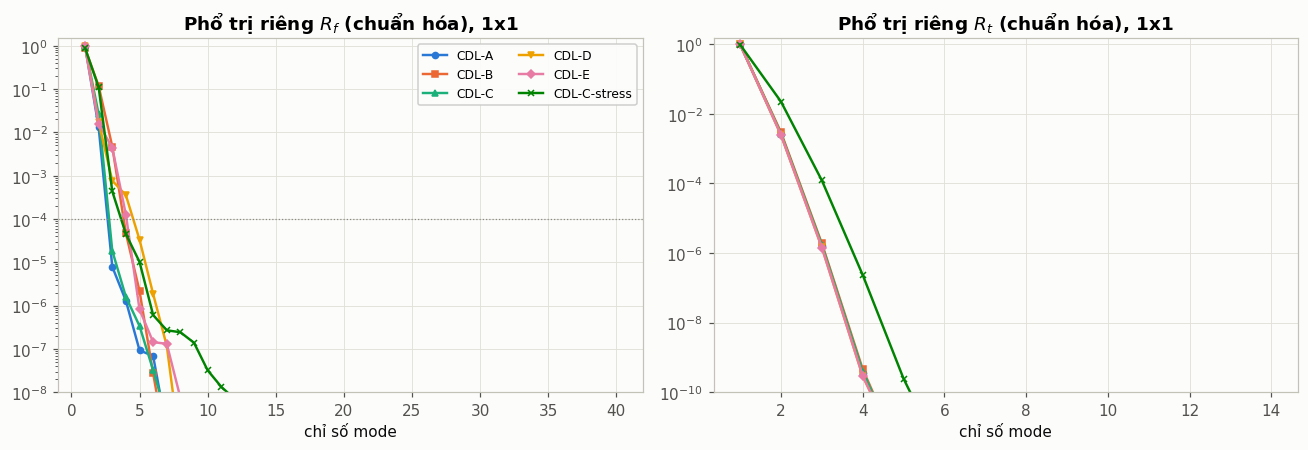

In [15]:
STATS = {}
t0 = time.time()
for sk, su in SETUPS.items():
    for ck in CHANNEL_KEYS:
        p = OUT_DIR / 'stats' / f'claude_stats_{sk}_{ck}.pt'
        if p.exists():
            STATS[(sk, ck)] = torch.load(p, map_location='cpu', weights_only=True)
        else:
            STATS[(sk, ck)] = channel_statistics(su, make_gen(su, CHANNELS[ck]))
            torch.save(STATS[(sk, ck)], p)
print(f'Channel statistics for {len(STATS)} (config, channel) pairs: {time.time() - t0:.1f} s')
rank_tab = pd.DataFrame([{'config': sk, 'channel': ck, 'r_t': STATS[(sk, ck)]['rt'], 'r_f': STATS[(sk, ck)]['rf'],
                          'R = r_t r_f': STATS[(sk, ck)]['rt'] * STATS[(sk, ck)]['rf'],
                          'energy captured [%]': 100 * STATS[(sk, ck)]['captured']} for sk, ck in STATS])
print(rank_tab.pivot(index='channel', columns='config', values='R = r_t r_f').loc[CHANNEL_KEYS])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ch_cols = dict(zip(CHANNEL_KEYS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']))
ch_mk = dict(zip(CHANNEL_KEYS, ['o', 's', '^', 'v', 'D', 'x']))
sk0 = ANT_CONFIGS[0]
for ck in CHANNEL_KEYS:
    st = STATS[(sk0, ck)]
    axs[0].semilogy(np.arange(1, 41), st['mu_f'].mean(0)[:40].clamp_min(1e-12).numpy(), color=ch_cols[ck], marker=ch_mk[ck],
                    ms=4, lw=1.6, label=ck)
    axs[1].semilogy(np.arange(1, 15), st['mu_t'].mean(0).clamp_min(1e-12).numpy(), color=ch_cols[ck], marker=ch_mk[ck],
                    ms=4, lw=1.6, label=ck)
axs[0].set_title(f'Phổ trị riêng $R_f$ (chuẩn hóa), {sk0}'); axs[0].set_xlabel('chỉ số mode'); axs[0].set_ylim(1e-8, 1.5)
axs[1].set_title(f'Phổ trị riêng $R_t$ (chuẩn hóa), {sk0}'); axs[1].set_xlabel('chỉ số mode'); axs[1].set_ylim(1e-10, 1.5)
axs[0].axhline(1e-4, color=MUTED, lw=0.8, ls=':')
axs[0].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(fig_path('channel_rank'), dpi=150); plt.show()

## 6. Công cụ thí nghiệm

* **Hiệu chỉnh dải SNR** (cho mỗi cấu hình/kênh): quét thô từng 1 dB với Perfect CSI và B0 để tìm vùng waterfall.
  * Dải huấn luyện: $[E_{\text{perf}}-1.5,\ E_{\text{B0}}+1]$ dB. Dải này phủ waterfall của **cả** bộ thu tốt (LC-AE) lẫn bộ thu LS (B1), nên công bằng cho mọi hệ thống.
  * Lưới đánh giá bắt đầu từ $E_{	ext{perf}}-1$ dB, bước 0.5 dB. Nếu khoảng cách giữa Perfect CSI và B0 lớn hơn 8 dB (waterfall thoải, thường gặp ở MIMO 2×2 khi kênh gần phẳng trong slot), bước tăng lên 1 dB.
  * Nếu B0 có **error floor** (không bao giờ xuống dưới 1e-2, ví dụ ở 30 m/s), mốc của B0 được chặn tại $E_{	ext{perf}}(10^{-2})+12$ dB.
* **Huấn luyện:** dùng một "pool" 16 384 realization kênh sinh trước (nhanh hơn khoảng 2× so với sinh mới mỗi vòng). Đánh giá BLER luôn dùng kênh **mới**, theo paired seeds.
* **RL (P09, [3]):** xen kẽ một bước RX (BCE, không nhiễu thăm dò) với một bước TX. Bước TX dùng surrogate REINFORCE với nhiễu thăm dò phương sai 0.01, cộng gradient qua demapper khi $y$ cố định (bộ thu biết chòm sao). Bước này **không** cần đạo hàm qua kênh. Cuối cùng tinh chỉnh RX 500 vòng. P09 dùng 10 bước RX cho mỗi bước TX vì RX của nó là MLP; RX của LC-AE chỉ có vài chục tham số nên 1 bước là đủ.

In [16]:
class ChannelPool:
    def __init__(self, gen, size, batch=512):
        with torch.no_grad():
            self.h = torch.cat([gen(batch) for _ in range(max(size // batch, 1))])

    def __call__(self, B):
        return self.h[torch.randint(0, self.h.shape[0], (B,), device=device)]


def build_link(su, gen, kind, stats):
    tx = {'perfect': QAMConstellation, 'B0': QAMConstellation, 'A1': QAMConstellation, 'B1': FreeConstellation,
          'A2': FreeConstellation, 'B2': FreeConstellation, 'LC2D': SymGSConstellation,
          'LC2D-RL': SymGSConstellation, 'LC1D': NUC1DConstellation}[kind]()
    if kind == 'perfect':
        ce = None
    elif kind in ('B0', 'B1', 'B2'):
        ce = LSnnEstimator(su)
    else:
        ce = LRLMMSEEstimator(su, stats, trainable=(kind != 'A1'))
    dm = {'perfect': lambda: APPDemapper2D(False), 'B0': lambda: APPDemapper2D(False), 'A1': lambda: APPDemapper2D(False),
          'B1': NeuralDemapperP09, 'A2': NeuralDemapperP09, 'B2': FiLMDemapper, 'LC2D': APPDemapper2D,
          'LC2D-RL': APPDemapper2D, 'LC1D': lambda: APPDemapper1D(True)}[kind]()
    link = OFDMLink(su, gen, tx, ce, dm).to(device)
    if isinstance(ce, LRLMMSEEstimator) and kind == 'A1':
        ce.freeze()
    return link.eval()


def freeze_link(link):
    if isinstance(link.rx.ce, LRLMMSEEstimator):
        link.rx.ce.freeze()
    return link.eval()


def train_rl(link, rec, rng, batch=TRAIN_BATCH, seed=0, label='', val_ebnos=None):
    tx_params = list(link.tx.parameters())
    rx_params = [p for p in link.rx.parameters() if p.requires_grad]
    opt_tx, opt_rx = torch.optim.Adam(tx_params, lr=rec['lr']), torch.optim.Adam(rx_params, lr=rec['lr'])
    n_tot = rec['alt'] + rec['ft']
    sch = [torch.optim.lr_scheduler.CosineAnnealingLR(o, n, eta_min=rec['lr_final'])
           for o, n in ((opt_tx, rec['alt']), (opt_rx, n_tot))]
    hist = {'it': [], 'loss': [], 'val_it': [], 'val': []}
    config.seed = seed
    link.rx.ce.unfreeze(); link.train()
    t0 = time.perf_counter()
    for i in range(n_tot):
        _, rx_loss = link.rl_losses(batch, sample_ebno(batch, rng), 0.0)          # receiver step
        opt_rx.zero_grad(set_to_none=True); rx_loss.backward(); opt_rx.step(); sch[1].step()
        if i < rec['alt']:                                                      # transmitter step (RL)
            tx_loss, rx_l2 = link.rl_losses(batch, sample_ebno(batch, rng), rec['var'])
            opt_tx.zero_grad(set_to_none=True); (tx_loss + rx_l2).backward(); opt_tx.step(); sch[0].step()
        if i % 25 == 0 or i == n_tot - 1:
            hist['it'].append(i); hist['loss'].append(rx_loss.item())
        if i % 250 == 0:
            print(f'\r  {label} it {i:5d}/{n_tot}  BCE {rx_loss.item():.4f}  {time.perf_counter() - t0:6.0f}s', end='', flush=True)
    dt = time.perf_counter() - t0
    link.eval()
    freeze_link(link)
    if val_ebnos is not None:
        hist['val_it'].append(n_tot); hist['val'].append(bmd_rate(link, val_ebnos))
    link.rx.ce.unfreeze()
    print(f'\r  {label} done: {rec["alt"]} alternating + {rec["ft"]} RX fine-tuning it in {dt / 60:.1f} min' + ' ' * 20)
    info = dict(iters=n_tot, forward_passes=2 * rec['alt'] + rec['ft'], batch=batch, time_s=dt,
                ms_per_iter=1e3 * dt / n_tot, trainable=count_trainable(link), lr=rec['lr'], rng=list(rng))
    return hist, info


@torch.no_grad()
def calibrate(perfect, b0, seed, batch=64, nb=2):
    def first_below(link, thr, start, stop):
        for eb in np.arange(start, stop + 1e-9, 1.0):
            config.seed = seed + int(round(eb * 10))
            e_ = n_ = 0
            for _ in range(nb):
                b, bh = link(batch, float(eb))
                blk = (b != bh).any(-1)
                e_ += int(blk.sum()); n_ += blk.numel()
            if e_ / n_ < thr:
                return float(eb)
        return None
    e_perf = first_below(perfect, 0.9, -8.0, 40.0)
    e_p2 = first_below(perfect, 1e-2, e_perf, e_perf + 30.0) or e_perf + 30.0
    e_b0 = first_below(b0, 1e-2, e_perf, e_p2 + 12.0)
    floor = e_b0 is None                       # B0 never reaches 1e-2 (error floor, e.g. 30 m/s)
    if floor:
        e_b0 = e_p2 + 12.0
    step = EVAL['step'] if e_b0 - e_perf <= 8.0 else 2 * EVAL['step']       # gentle (MIMO) slopes: coarser grid
    return dict(e_perf=e_perf, e_perf_1e2=e_p2, e_b0=e_b0, b0_floor=floor, step=step,
                train=(e_perf - 1.5, e_b0 + 1.0),
                grid=[float(v) for v in np.arange(e_perf - 1.0, e_b0 + 6.0 + 1e-9, step)])

### 6.1 Vòng lặp thí nghiệm cho một (cấu hình, kênh)

Các hệ thống được so sánh:

| Mã | TX | Ước lượng kênh | Demapper | Huấn luyện |
|---|---|---|---|---|
| `perfect` | 64-QAM | kênh thật | APP | — (cận dưới) |
| **B0** | 64-QAM | LS-nn | APP | — |
| **B1** | Free-64 | LS-nn | MLP-P09 | 10 000 vòng (P09) |
| A1 | 64-QAM | LR-LMMSE (thống kê) | APP | — (ablation: chỉ đổi CE) |
| **LC-AE-2D** | SymGS-2D | LR-LMMSE | APP-2D + β | 3 000 vòng |
| **LC-AE-1D** | NUC-1D | LR-LMMSE | APP-1D + β | 3 000 vòng |
| A2 *(chỉ CDL-C)* | Free-64 | LR-LMMSE | MLP-P09 | 10 000 vòng (ablation: MLP so với APP) |
| B2 *(chỉ CDL-C)* | Free-64 | LS-nn | FiLM | 10 000 vòng |
| LC-AE-2D-RL *(chỉ CDL-C)* | SymGS-2D | LR-LMMSE | APP-2D + β | RL, không đạo hàm qua kênh |

Với **CDL-C-stress**, ngoài các mô hình chuyên biệt, ta còn đánh giá các mô hình **huấn luyện trên CDL-C** (`@C`) để đo độ bền khi thống kê kênh lệch.

In [17]:
CURVES, TRAIN_LOG, CALIB = {}, {}, {}
MAIN_SYSTEMS = ['perfect', 'B0', 'A1', 'B1', 'LC2D', 'LC1D']
EXTRA_SYSTEMS = ['A2', 'B2', 'LC2D-RL']
DIAG_SYSTEMS = ['A2-APP']          # diagnostic: A2's learned free-64 TX and CE, but the analytic APP demapper
MISMATCH = ['B1', 'LC2D', 'LC1D']


def run_setting(sk, ck):
    t_set = time.time()
    su, spec, st = SETUPS[sk], CHANNELS[ck], STATS[(sk, ck)]
    tag = f'{sk}_{ck}'
    si, ci = list(SETUP_SPECS).index(sk), list(CHANNELS).index(ck)
    seed_base = 1_000_000 + 100_000 * si + 10_000 * ci
    gen = make_gen(su, spec)
    links = {k: build_link(su, gen, k, st) for k in ('perfect', 'B0', 'A1')}
    cp = OUT_DIR / 'stats' / f'claude_calib_{tag}.json'
    if cp.exists():
        CALIB[(sk, ck)] = json.loads(cp.read_text())
    else:
        CALIB[(sk, ck)] = calibrate(links['perfect'], links['B0'], seed_base + 5000)
        cp.write_text(json.dumps(CALIB[(sk, ck)]))
    cal = CALIB[(sk, ck)]
    rng = tuple(cal['train'])
    val_ebnos = [rng[0] + (rng[1] - rng[0]) / 3, rng[0] + 2 * (rng[1] - rng[0]) / 3]
    log(f'[{tag}] r_t={st["rt"]} r_f={st["rf"]} | perfect<0.9 @ {cal["e_perf"]} dB, <1e-2 @ {cal["e_perf_1e2"]} dB | '
        f'B0<1e-2 @ {cal["e_b0"]} dB{" (error floor)" if cal["b0_floor"] else ""} | train {rng} | grid step {cal["step"]} dB')
    pool = None
    for k in MAIN_SYSTEMS[3:] + (EXTRA_SYSTEMS if ck == 'CDL-C' else []):
        link = build_link(su, gen, k, st)
        wp = OUT_DIR / 'weights' / f'claude_{tag}_{k}.pt'
        if wp.exists():
            ck_ = torch.load(wp, map_location=device, weights_only=True)
            link.load_state_dict(ck_['state_dict']); TRAIN_LOG[(sk, ck, k)] = ck_['log']
            print(f'  {k}: loaded {wp.name}')
        else:
            if pool is None:
                pool = ChannelPool(gen, POOL_SIZE)
            link.set_channel(pool)
            if isinstance(link.rx.ce, LRLMMSEEstimator):
                link.rx.ce.unfreeze()
            seed = seed_base + 100 * (list(STYLE).index(k))
            if k == 'LC2D-RL':
                hist, info = train_rl(link, RECIPES[k], rng, seed=seed, label=f'{tag} {k}', val_ebnos=val_ebnos)
            else:
                r_ = RECIPES[k]
                hist, info = train_conventional(link, r_['iters'], r_['lr'], rng, lr_final=r_['lr_final'], seed=seed,
                                                label=f'{tag} {k}', val_ebnos=val_ebnos)
            link.set_channel(gen)
            TRAIN_LOG[(sk, ck, k)] = {'hist': hist, 'info': info}
            torch.save({'state_dict': link.state_dict(), 'log': TRAIN_LOG[(sk, ck, k)]}, wp)
            log(f'[{tag}] trained {k}: {info["time_s"] / 60:.1f} min, {info["trainable"]} params')
        links[k] = freeze_link(link)
    del pool
    if 'A2' in links:                  # same TX + CE as A2, MLP replaced by APP -> separates geometry from demapper
        links['A2-APP'] = OFDMLink(su, gen, links['A2'].tx, links['A2'].rx.ce, APPDemapper2D(False).to(device)).eval()
    if ck == 'CDL-C-stress' and (sk, 'CDL-C') in STATS:
        for k in MISMATCH:
            wp = OUT_DIR / 'weights' / f'claude_{sk}_CDL-C_{k}.pt'
            if wp.exists():
                link = build_link(su, gen, k, STATS[(sk, 'CDL-C')])
                link.load_state_dict(torch.load(wp, map_location=device, weights_only=True)['state_dict'])
                links[f'{k}@C'] = freeze_link(link)
    gentle = cal['step'] > EVAL['step']
    stop_bler = EVAL['gentle_stop_bler'] if gentle else EVAL['stop_bler']
    max_cw = EVAL['gentle_max_cw'] if gentle else EVAL['max_cw']
    for k, link in links.items():
        CURVES[(sk, ck, k)] = cached_pickle(
            OUT_DIR / 'curves' / f'claude_{tag}_{k}.pkl',
            lambda: simulate_bler(link, cal['grid'], EVAL['batch'], EVAL['target_err'], max_cw,
                                  stop_bler, seed_base, label=f'{tag} {k}', floor_ratio=0.8 if gentle else 0.7))
    del links
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    log(f'[{tag}] done in {(time.time() - t_set) / 60:.1f} min')


def run_config(sk):
    t0 = time.time()
    for ck in CHANNEL_KEYS:
        run_setting(sk, ck)
    log(f'=== config {sk} finished in {(time.time() - t0) / 60:.1f} min ===')

## 7. Thí nghiệm

### 7.1 SISO 1×1

In [18]:
run_config('1x1')

[2026-09-27 03:38:38] [1x1_CDL-A] r_t=2 r_f=2 | perfect<0.9 @ 6.0 dB, <1e-2 @ 8.0 dB | B0<1e-2 @ 11.0 dB | train (4.5, 12.0) | grid step 0.5 dB


  B1: loaded claude_1x1_CDL-A_B1.pt
  LC2D: loaded claude_1x1_CDL-A_LC2D.pt
  LC1D: loaded claude_1x1_CDL-A_LC1D.pt
[2026-09-27 03:38:38] [1x1_CDL-A] done in 0.0 min


[2026-09-27 03:38:38] [1x1_CDL-B] r_t=2 r_f=3 | perfect<0.9 @ 6.0 dB, <1e-2 @ 10.0 dB | B0<1e-2 @ 12.0 dB | train (4.5, 13.0) | grid step 0.5 dB


  B1: loaded claude_1x1_CDL-B_B1.pt
  LC2D: loaded claude_1x1_CDL-B_LC2D.pt
  LC1D: loaded claude_1x1_CDL-B_LC1D.pt
[2026-09-27 03:38:38] [1x1_CDL-B] done in 0.0 min


[2026-09-27 03:38:38] [1x1_CDL-C] r_t=2 r_f=2 | perfect<0.9 @ 6.0 dB, <1e-2 @ 9.0 dB | B0<1e-2 @ 12.0 dB | train (4.5, 13.0) | grid step 0.5 dB


  B1: loaded claude_1x1_CDL-C_B1.pt
  LC2D: loaded claude_1x1_CDL-C_LC2D.pt
  LC1D: loaded claude_1x1_CDL-C_LC1D.pt
  A2: loaded claude_1x1_CDL-C_A2.pt
  B2: loaded claude_1x1_CDL-C_B2.pt
  LC2D-RL: loaded claude_1x1_CDL-C_LC2D-RL.pt
[2026-09-27 03:38:38] [1x1_CDL-C] done in 0.0 min


... (4 outputs left out)

[2026-09-27 03:38:38] [1x1_CDL-C-stress] r_t=2 r_f=3 | perfect<0.9 @ 6.0 dB, <1e-2 @ 10.0 dB | B0<1e-2 @ 22.0 dB (error floor) | train (4.5, 23.0) | grid step 1.0 dB


  B1: loaded claude_1x1_CDL-C-stress_B1.pt
  LC2D: loaded claude_1x1_CDL-C-stress_LC2D.pt
  LC1D: loaded claude_1x1_CDL-C-stress_LC1D.pt


[2026-09-27 03:38:38] [1x1_CDL-C-stress] done in 0.0 min


[2026-09-27 03:38:38] === config 1x1 finished in 0.0 min ===


### 7.2 SIMO 1×2

In [19]:
if '1x2' in ANT_CONFIGS:
    run_config('1x2')

[2026-09-27 03:38:38] [1x2_CDL-A] r_t=2 r_f=2 | perfect<0.9 @ 3.0 dB, <1e-2 @ 5.0 dB | B0<1e-2 @ 8.0 dB | train (1.5, 9.0) | grid step 0.5 dB


  B1: loaded claude_1x2_CDL-A_B1.pt
  LC2D: loaded claude_1x2_CDL-A_LC2D.pt
  LC1D: loaded claude_1x2_CDL-A_LC1D.pt
[2026-09-27 03:38:38] [1x2_CDL-A] done in 0.0 min


[2026-09-27 03:38:38] [1x2_CDL-B] r_t=2 r_f=3 | perfect<0.9 @ 3.0 dB, <1e-2 @ 6.0 dB | B0<1e-2 @ 9.0 dB | train (1.5, 10.0) | grid step 0.5 dB


  B1: loaded claude_1x2_CDL-B_B1.pt


  LC2D: loaded claude_1x2_CDL-B_LC2D.pt
  LC1D: loaded claude_1x2_CDL-B_LC1D.pt
[2026-09-27 03:38:38] [1x2_CDL-B] done in 0.0 min


[2026-09-27 03:38:38] [1x2_CDL-C] r_t=2 r_f=2 | perfect<0.9 @ 3.0 dB, <1e-2 @ 5.0 dB | B0<1e-2 @ 8.0 dB | train (1.5, 9.0) | grid step 0.5 dB


... (7 outputs left out)

  LC2D: loaded claude_1x2_CDL-E_LC2D.pt
  LC1D: loaded claude_1x2_CDL-E_LC1D.pt
[2026-09-27 03:38:38] [1x2_CDL-E] done in 0.0 min


[2026-09-27 03:38:38] [1x2_CDL-C-stress] r_t=2 r_f=3 | perfect<0.9 @ 3.0 dB, <1e-2 @ 6.0 dB | B0<1e-2 @ 18.0 dB (error floor) | train (1.5, 19.0) | grid step 1.0 dB

  B1: loaded claude_1x2_CDL-C-stress_B1.pt
  LC2D: loaded claude_1x2_CDL-C-stress_LC2D.pt
  LC1D: loaded claude_1x2_CDL-C-stress_LC1D.pt
[2026-09-27 03:38:38] [1x2_CDL-C-stress] done in 0.0 min


[2026-09-27 03:38:38] === config 1x2 finished in 0.0 min ===


### 7.3 MIMO 2×2 (2 stream, LMMSE)

In [20]:
if '2x2' in ANT_CONFIGS:
    run_config('2x2')

[2026-09-27 03:38:38] [2x2_CDL-A] r_t=2 r_f=2 | perfect<0.9 @ -1.0 dB, <1e-2 @ 18.0 dB | B0<1e-2 @ 22.0 dB | train (-2.5, 23.0) | grid step 1.0 dB


  B1: loaded claude_2x2_CDL-A_B1.pt

  LC2D: loaded claude_2x2_CDL-A_LC2D.pt

  LC1D: loaded claude_2x2_CDL-A_LC1D.pt
[2026-09-27 03:38:38] [2x2_CDL-A] done in 0.0 min


[2026-09-27 03:38:38] [2x2_CDL-B] r_t=2 r_f=3 | perfect<0.9 @ -1.0 dB, <1e-2 @ 16.0 dB | B0<1e-2 @ 20.0 dB | train (-2.5, 21.0) | grid step 1.0 dB

  B1: loaded claude_2x2_CDL-B_B1.pt
  LC2D: loaded claude_2x2_CDL-B_LC2D.pt
  LC1D: loaded claude_2x2_CDL-B_LC1D.pt
[2026-09-27 03:38:38] [2x2_CDL-B] done in 0.0 min


... (12 outputs left out)

  B1: loaded claude_2x2_CDL-C-stress_B1.pt

  LC2D: loaded claude_2x2_CDL-C-stress_LC2D.pt
  LC1D: loaded claude_2x2_CDL-C-stress_LC1D.pt


[2026-09-27 03:38:39] [2x2_CDL-C-stress] done in 0.0 min


[2026-09-27 03:38:39] === config 2x2 finished in 0.0 min ===


## 8. Kết quả BLER

Mỗi hình ứng với một cấu hình anten và có 6 ô (6 kênh). Các ngưỡng Eb/N0 tại BLER $10^{-2}$ và $10^{-3}$ được nội suy log-tuyến tính.

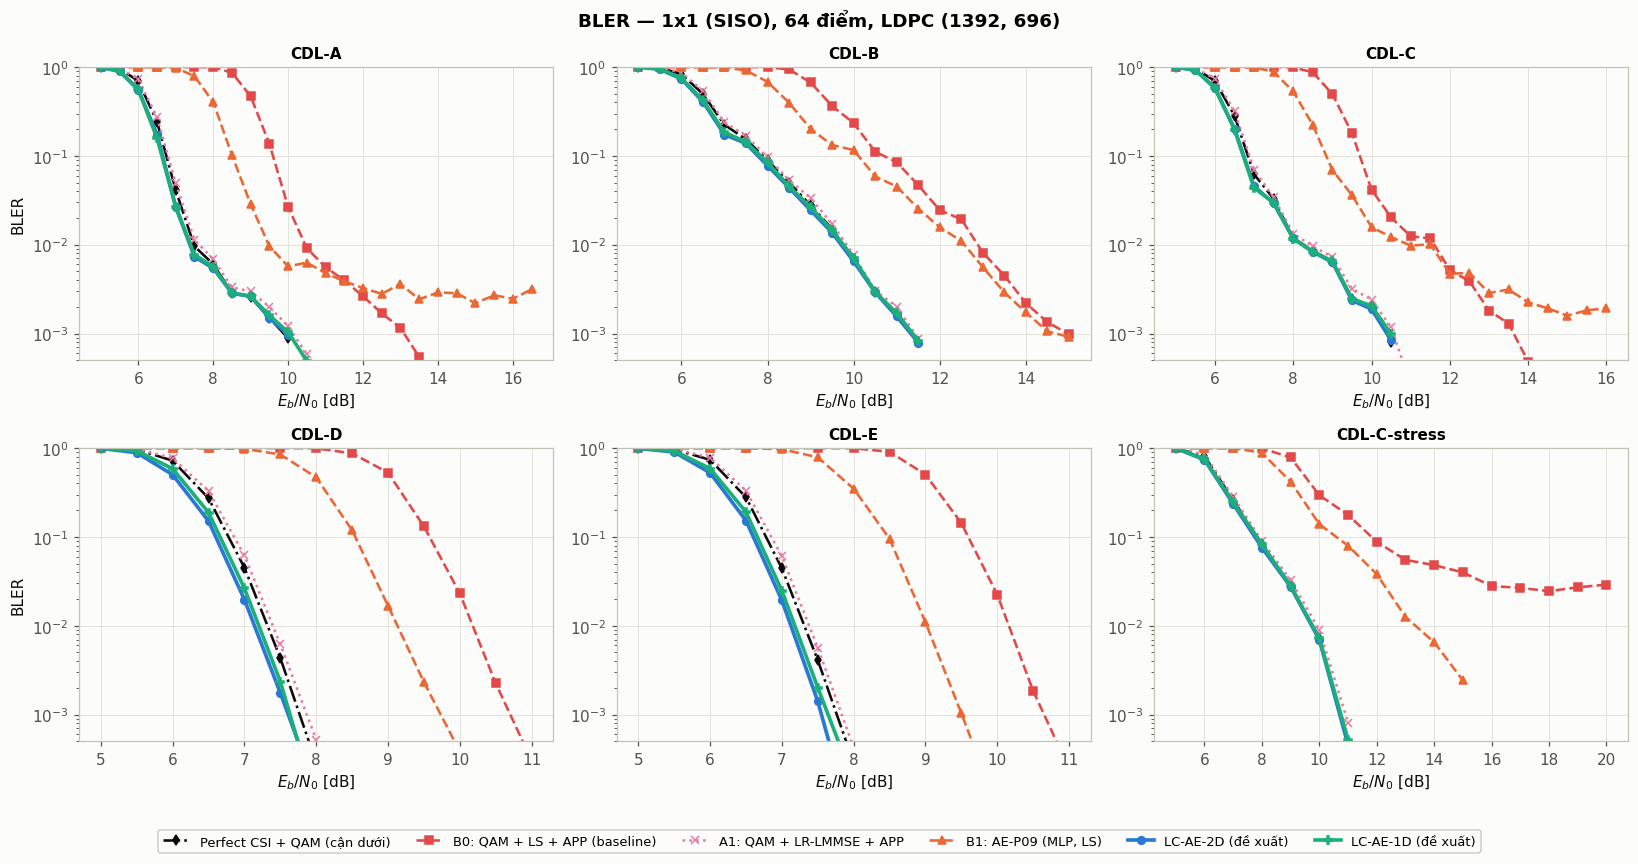

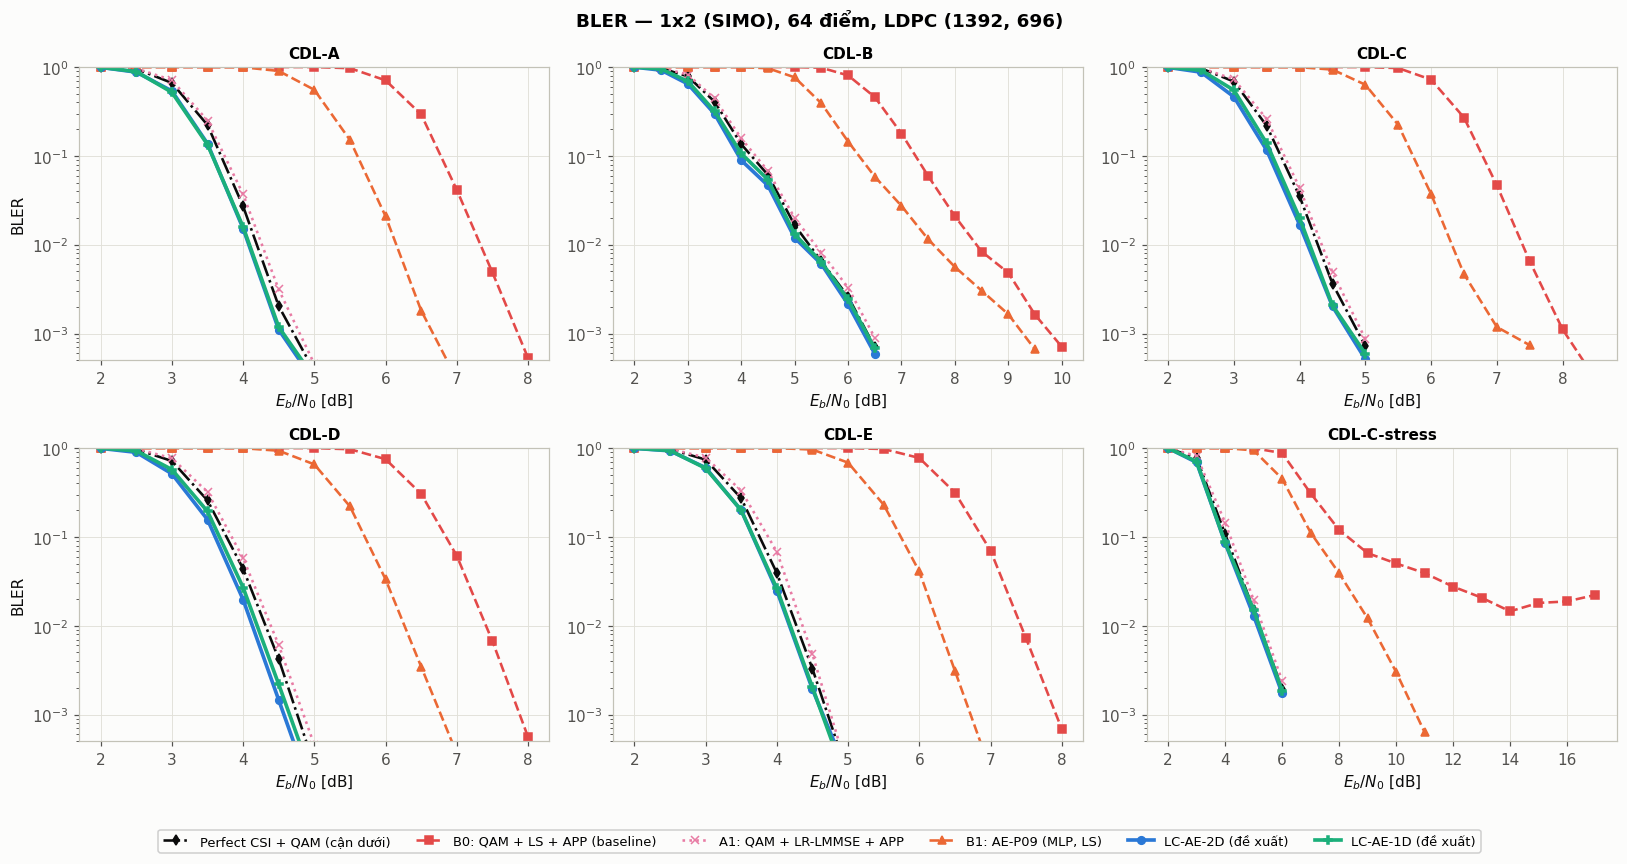

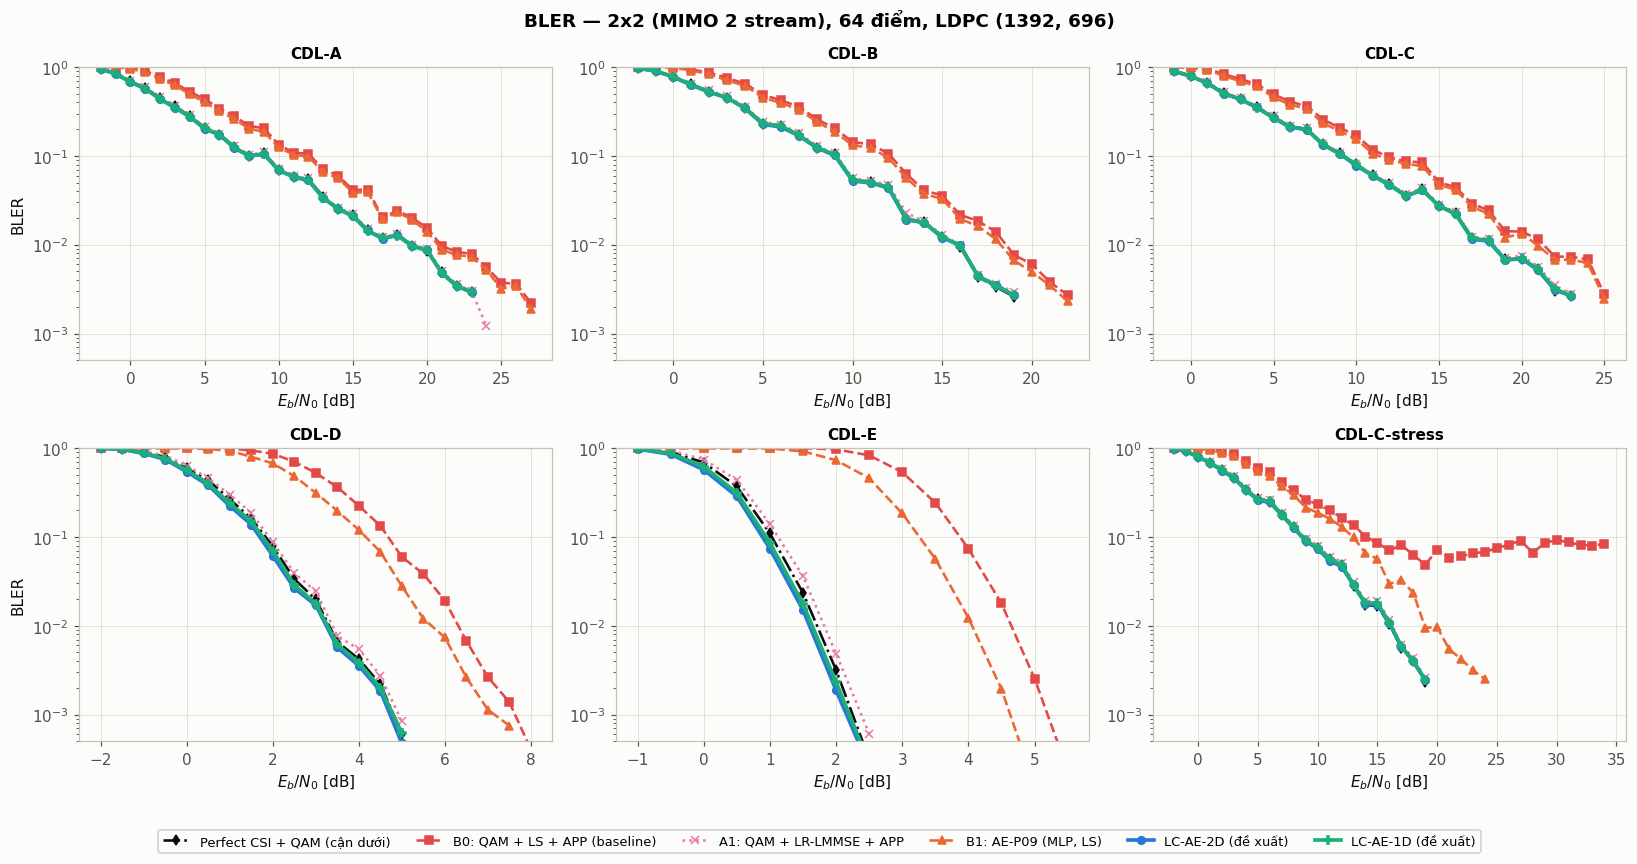

In [21]:
def plot_panel(ax, sk, ck, keys, title=None, ci=False):
    for k in keys:
        c_ = CURVES.get((sk, ck, k))
        if c_ is None:
            continue
        base = k.split('@')[0]
        lab, col, ls, mk = STYLE[base]
        if '@' in k:
            lab, ls = lab + ' — train CDL-C', ':'
        m = c_['bler'] > 0
        ax.semilogy(c_['ebno'][m], c_['bler'][m], color=col, ls=ls, marker=mk, ms=5,
                    mfc='none' if '@' in k else col, label=lab, lw=2.4 if base in ('LC2D', 'LC1D') else 1.7)
        if ci:
            lo, hi = wilson_ci(c_['blk_err'][m], c_['blocks'][m])
            ax.fill_between(c_['ebno'][m], lo, hi, color=col, alpha=0.12, lw=0)
    ax.set_ylim(5e-4, 1.0)
    ax.set_title(title or ck, fontsize=10)
    ax.set_xlabel(r'$E_b/N_0$ [dB]')


for sk in ANT_CONFIGS:
    n = len(CHANNEL_KEYS)
    nc = 3 if n > 2 else n
    nr = int(math.ceil(n / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(5.0 * nc, 3.9 * nr), squeeze=False)
    for i, ck in enumerate(CHANNEL_KEYS):
        ax = axs[i // nc][i % nc]
        plot_panel(ax, sk, ck, MAIN_SYSTEMS)
        if i % nc == 0:
            ax.set_ylabel('BLER')
    for j in range(n, nr * nc):
        axs[j // nc][j % nc].axis('off')
    h_, l_ = axs[0][0].get_legend_handles_labels()
    fig.legend(h_, l_, loc='lower center', ncol=len(l_), fontsize=8.5, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(f'BLER — {sk} ({"SISO" if sk == "1x1" else "SIMO" if sk == "1x2" else "MIMO 2 stream"}), '
                 f'64 điểm, LDPC (1392, 696)', fontweight='bold')
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(fig_path(f'bler_{sk}'), dpi=150, bbox_inches='tight'); plt.show()

In [22]:
ROWS = []
for (sk, ck, k), c_ in CURVES.items():
    row = dict(config=sk, channel=ck, system=k, e1e2=snr_at_bler(c_, 1e-2), e1e3=snr_at_bler(c_, 1e-3))
    tl = TRAIN_LOG.get((sk, ck, k.split('@')[0])) if '@' not in k else TRAIN_LOG.get((sk, 'CDL-C', k.split('@')[0]))
    row['train_min'] = tl['info']['time_s'] / 60 if tl else 0.0
    ROWS.append(row)
TH = pd.DataFrame(ROWS)
for ref in ('perfect', 'B0', 'B1'):
    m_ = TH.set_index(['config', 'channel', 'system'])
    for t in ('e1e2', 'e1e3'):
        refv = TH.apply(lambda r: m_.loc[(r.config, r.channel, ref), t] if (r.config, r.channel, ref) in m_.index
                        else np.nan, axis=1)
        TH[f'gain_vs_{ref}_{t}'] = refv - TH[t]          # > 0: system needs less Eb/N0 than the reference
TH.to_csv(OUT_DIR / 'claude_thresholds.csv', index=False, encoding='utf-8-sig')

pd.set_option('display.width', 200)
for t, name in (('e1e2', 'BLER 1e-2'), ('e1e3', 'BLER 1e-3')):
    piv = TH[TH.system.isin(MAIN_SYSTEMS)].pivot_table(index=['config', 'channel'], columns='system', values=t)
    piv = piv[[k for k in MAIN_SYSTEMS if k in piv.columns]]
    print(f'\nEb/N0 [dB] needed for {name}:')
    show_df(piv.round(2))


Eb/N0 [dB] needed for BLER 1e-2:


system               perfect     B0     A1     B1   LC2D   LC1D
config channel                                                 
1x1    CDL-A            7.49  10.46   7.63   9.48   7.38   7.40
       CDL-B            9.76  12.88   9.84  12.57   9.71   9.76
       CDL-C            8.26  11.60   8.44  10.95   8.23   8.23
       CDL-C-stress     9.76    NaN   9.92  13.35   9.74   9.76
       CDL-D            7.32  10.18   7.40   9.13   7.14   7.20
       CDL-E            7.31  10.16   7.38   9.02   7.13   7.18
1x2    CDL-A            4.19   7.33   4.26   6.15   4.08   4.09
       CDL-B            5.27   8.40   5.38   7.60   5.13   5.19
       CDL-C            4.28   7.39   4.34   6.32   4.12   4.15
       CDL-C-stress     5.20    NaN   5.32   9.14   5.13   5.20
       CDL-D            4.32   7.41   4.39   6.27   4.13   4.20
       CDL-E            4.28   7.43   4.36   6.27   4.18   4.19
2x2    CDL-A           18.88  20.92  18.98  20.72  18.92  18.85
       CDL-B           15.81  18.56  16.01  18.25  15.93  15.86
       CDL-C           18.20  21.31  18.30  20.91  18.19  18.22
       CDL-C-stress    16.06    NaN  16.24  18.95  16.10  16.13
       CDL-D            3.31   6.31   3.39   5.69   3.24   3.27
       CDL-E            1.71   4.65   1.82   4.06   1.60   1.64


Eb/N0 [dB] needed for BLER 1e-3:


system               perfect     B0     A1     B1   LC2D   LC1D
config channel                                                 
1x1    CDL-A            9.88  13.10  10.13    NaN   9.97  10.02
       CDL-B           11.34  14.96  11.42  14.69  11.33  11.37
       CDL-C           10.39  13.63  10.55    NaN  10.39  10.49
       CDL-C-stress    10.72    NaN  10.91    NaN  10.71  10.75
       CDL-D            7.77  10.70   7.87   9.73   7.61   7.63
       CDL-E            7.77  10.65   7.83   9.51   7.55   7.64
1x2    CDL-A            4.71   7.86   4.80   6.67   4.54   4.56
       CDL-B            6.36   9.79   6.46   9.27   6.30   6.35
       CDL-C            4.90   8.04   4.96   7.18   4.76   4.79
       CDL-C-stress      NaN    NaN    NaN  10.71    NaN    NaN
       CDL-D            4.76   7.88   4.85   6.78   4.57   4.65
       CDL-E            4.71   7.92   4.76   6.72   4.65   4.64
2x2    CDL-D            4.81   7.63   4.93   7.15   4.73   4.80
       CDL-E            2.25   5.20   2.38   4.63   2.16   2.20

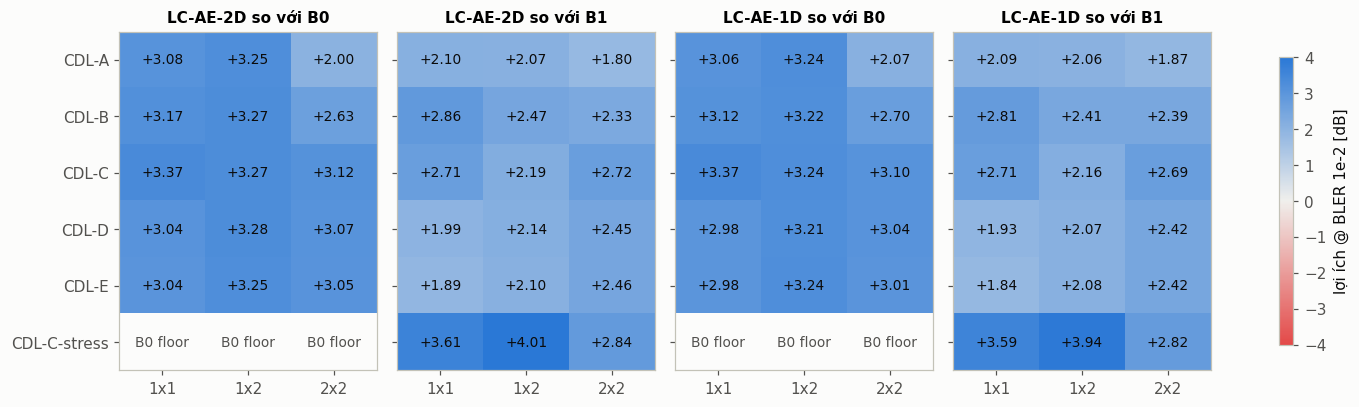

In [23]:
# Gain heat-maps (dB at BLER 1e-2): positive = proposed system needs less Eb/N0. Diverging red-grey-blue, 0 = grey.
div_cmap = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])
panels = [('LC2D', 'B0'), ('LC2D', 'B1'), ('LC1D', 'B0'), ('LC1D', 'B1')]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.0), gridspec_kw={'wspace': 0.08})
vmax = max(1.0, float(np.nanmax(np.abs(TH[TH.system.isin(['LC2D', 'LC1D'])][['gain_vs_B0_e1e2', 'gain_vs_B1_e1e2']].values))))
for a_i, (ax, (sysk, ref)) in enumerate(zip(axs, panels)):
    sub = TH[TH.system == sysk].pivot_table(index='channel', columns='config', values=f'gain_vs_{ref}_e1e2')
    sub = sub.reindex(index=CHANNEL_KEYS, columns=ANT_CONFIGS)
    im = ax.imshow(sub.values, cmap=div_cmap, vmin=-vmax, vmax=vmax, aspect='auto')
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            v = sub.values[i, j]
            ref_nan = np.isnan(TH[(TH.config == ANT_CONFIGS[j]) & (TH.channel == CHANNEL_KEYS[i]) & (TH.system == ref)]['e1e2']).all()
            txt = (f'{ref} floor' if ref_nan else '—') if np.isnan(v) else f'{v:+.2f}'
            ax.text(j, i, txt, ha='center', va='center', color=INK if not np.isnan(v) else INK2, fontsize=9)
    ax.set_xticks(range(len(ANT_CONFIGS)), ANT_CONFIGS)
    ax.set_yticks(range(len(CHANNEL_KEYS)), CHANNEL_KEYS if a_i == 0 else [''] * len(CHANNEL_KEYS))
    ax.set_title(f'{STYLE[sysk][0].split(" (")[0]} so với {ref}', fontsize=10); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.85, label='lợi ích @ BLER 1e-2 [dB]')
fig.savefig(fig_path('gain_heatmap'), dpi=150, bbox_inches='tight'); plt.show()

## 9. Ablation và độ bền

### 9.1 CDL-C: tách phần lợi ích

Chuỗi ablation: **B0** → **A1** (chỉ thay ước lượng kênh) → **LC-AE** (thêm shaping và hiệu chỉnh LLR). Ngoài ra so sánh **A2** (MLP-P09 với CE tốt) với **LC-AE-2D** (APP) để trả lời câu hỏi "MLP có cần thiết không?". **B2** là demapper FiLM nặng hơn theo report. **RL** là LC-AE-2D huấn luyện không cần đạo hàm kênh.

**A2-APP** (chẩn đoán) dùng *đúng* chòm sao Free-64 và CE mà A2 đã học, nhưng thay MLP bằng APP-2D (β = 1). So sánh cặp:
* A2 với A2-APP: đo phần lợi ích đến từ **demapper MLP**.
* A2-APP với LC-AE-2D: đo phần lợi ích đến từ **hình học chòm sao** (Free-64 so với SymGS-2D).

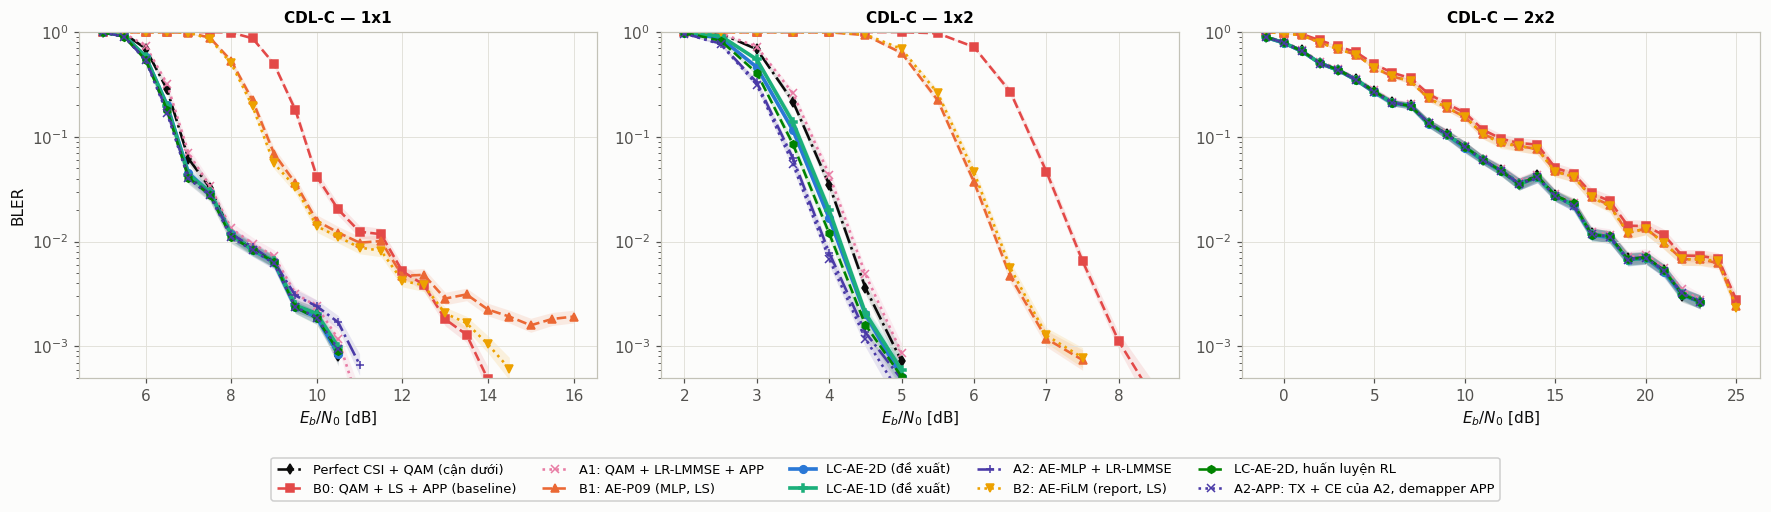

CDL-C: Eb/N0 [dB] @ BLER 1e-2


config,1x1,1x2,2x2
system,,,
perfect,8.26,4.28,18.20
B0,11.60,7.39,21.31
A1,8.44,4.34,18.30
B1,10.95,6.32,20.91
LC2D,8.23,4.12,18.19
LC1D,8.23,4.15,18.22
A2,8.29,3.94,18.22
B2,10.72,6.36,20.88
LC2D-RL,8.19,4.05,18.24



Gain decomposition [dB] at BLER 1e-2 (positive = improvement):


,CE: B0 -> A1,GS+calib: A1 -> LC-AE-2D,A1 -> LC-AE-1D,APP vs MLP: A2 -> LC-AE-2D,"MLP gain, same free-64 TX: A2-APP -> A2",free-64 vs SymGS geometry (APP): LC-AE-2D -> A2-APP,gap LC-AE-2D to perfect
config,,,,,,,
1x1,3.165,0.202,0.202,0.058,-0.129,0.072,-0.029
1x2,3.054,0.215,0.184,-0.180,-0.032,0.213,-0.154
2x2,3.010,0.115,0.088,0.029,-0.017,-0.012,-0.014


In [24]:
cfgs = [s for s in ANT_CONFIGS]
fig, axs = plt.subplots(1, len(cfgs), figsize=(5.4 * len(cfgs), 4.4), squeeze=False)
for i, sk in enumerate(cfgs):
    plot_panel(axs[0][i], sk, 'CDL-C', MAIN_SYSTEMS + EXTRA_SYSTEMS + DIAG_SYSTEMS, title=f'CDL-C — {sk}', ci=True)
    if i == 0:
        axs[0][i].set_ylabel('BLER')
h_, l_ = axs[0][0].get_legend_handles_labels()
fig.legend(h_, l_, loc='lower center', ncol=5, fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(fig_path('ablation_cdlc'), dpi=150, bbox_inches='tight'); plt.show()

abl = TH[(TH.channel == 'CDL-C')].pivot_table(index='system', columns='config', values='e1e2')
abl = abl.reindex(index=[k for k in MAIN_SYSTEMS + EXTRA_SYSTEMS + DIAG_SYSTEMS if k in abl.index], columns=ANT_CONFIGS)
print('CDL-C: Eb/N0 [dB] @ BLER 1e-2')
show_df(abl.round(2))
steps = []
for sk in ANT_CONFIGS:
    g = lambda k: abl.loc[k, sk] if k in abl.index else np.nan
    steps.append({'config': sk, 'CE: B0 -> A1': g('B0') - g('A1'), 'GS+calib: A1 -> LC-AE-2D': g('A1') - g('LC2D'),
                  'A1 -> LC-AE-1D': g('A1') - g('LC1D'), 'APP vs MLP: A2 -> LC-AE-2D': g('A2') - g('LC2D'),
                  'MLP gain, same free-64 TX: A2-APP -> A2': g('A2-APP') - g('A2'),
                  'free-64 vs SymGS geometry (APP): LC-AE-2D -> A2-APP': g('LC2D') - g('A2-APP'),
                  'gap LC-AE-2D to perfect': g('LC2D') - g('perfect')})
ABL_STEPS = pd.DataFrame(steps).set_index('config')
print('\nGain decomposition [dB] at BLER 1e-2 (positive = improvement):')
show_df(ABL_STEPS.round(3))

### 9.2 CDL-C-stress (DS 300 ns, 30 m/s): mô hình chuyên biệt so với mô hình huấn luyện trên CDL-C

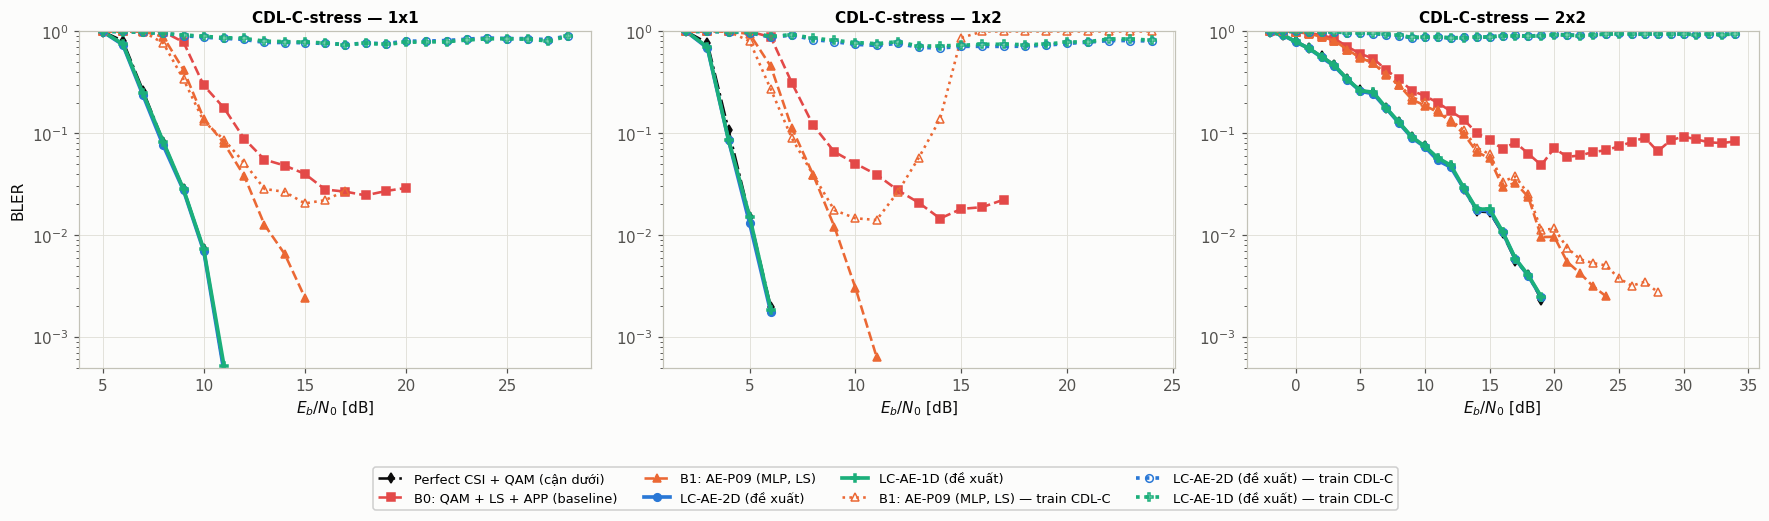

config,1x1,1x2,2x2
system,,,
A1,9.92,5.32,16.24
B1,13.35,9.14,18.95
B1@C,NaN,NaN,20.34
LC1D,9.76,5.20,16.13
LC2D,9.74,5.13,16.10
perfect,9.76,5.20,16.06


In [25]:
fig, axs = plt.subplots(1, len(ANT_CONFIGS), figsize=(5.4 * len(ANT_CONFIGS), 4.4), squeeze=False)
for i, sk in enumerate(ANT_CONFIGS):
    plot_panel(axs[0][i], sk, 'CDL-C-stress', ['perfect', 'B0', 'B1', 'LC2D', 'LC1D', 'B1@C', 'LC2D@C', 'LC1D@C'],
               title=f'CDL-C-stress — {sk}')
    if i == 0:
        axs[0][i].set_ylabel('BLER')
h_, l_ = axs[0][0].get_legend_handles_labels()
fig.legend(h_, l_, loc='lower center', ncol=4, fontsize=8.5, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(rect=(0, 0.09, 1, 1))
fig.savefig(fig_path('stress_mismatch'), dpi=150, bbox_inches='tight'); plt.show()
stress = TH[TH.channel == 'CDL-C-stress'].pivot_table(index='system', columns='config', values='e1e2')
show_df(stress.round(2))

## 10. Benchmark độ phức tạp

Mọi phép đo chạy trên cùng máy, với **cùng đoạn xử lý**: từ tín hiệu nhận $y$ (miền tần số, sau FFT) đến LLR của cả slot. LDPC decoder dùng chung cho mọi hệ thống nên được đo riêng. Chòm sao đã học được "đông cứng" thành bảng tra, và bộ lọc LR-LMMSE được tính sẵn.

| Chỉ số | Cách đo |
|---|---|
| Tham số | số tham số huấn luyện được (TX + RX) và kích thước `state_dict` |
| FLOPs/slot | đếm giải tích **mọi** phép toán thực (1 phép nhân-cộng phức = 8 FLOP; exp/log/div = 1), tách theo CE / cân bằng / demapper. Đối chiếu với `FlopCounterMode` cho phần nhân ma trận |
| GPU | latency (median) cho B = 1 và B = 128 slot, ở chế độ eager (PyTorch thường) và **CUDA Graph** (loại bỏ overhead Python và launch kernel, như khi triển khai thật); throughput, bộ nhớ đỉnh khi suy luận, % GPU util (`nvidia-smi`) |
| CPU | latency cho B = 1 và B = 32 slot, với 1 luồng và 24 luồng. Flush-denormal được bật cho mọi hệ thống |
| Huấn luyện | ms/vòng (B = 32 slot), bộ nhớ đỉnh, tổng thời gian đã dùng |

In [26]:
from torch.utils.flop_counter import FlopCounterMode


class GpuUtilSampler:
    def __enter__(self):
        self.vals = []
        try:
            self.p = subprocess.Popen(['nvidia-smi', '--query-gpu=utilization.gpu', '--format=csv,noheader,nounits',
                                       '-lms', '100'], stdout=subprocess.PIPE, text=True)
            self.t = threading.Thread(target=self._read, daemon=True); self.t.start()
        except OSError:
            self.p = None
        return self

    def _read(self):
        for line in self.p.stdout:
            try:
                self.vals.append(float(line.strip()))
            except ValueError:
                pass

    def __exit__(self, *a):
        if self.p is not None:
            self.p.terminate()

    @property
    def mean(self):
        v = self.vals[2:] if len(self.vals) > 4 else self.vals
        return float(np.mean(v)) if v else float('nan')


def bench(fn, cuda=True, min_time=1.0, max_reps=300, min_reps=3, warmup=3):
    for _ in range(warmup):
        fn()
    if cuda:
        torch.cuda.synchronize()
    ts, tot = [], 0.0
    while (tot < min_time or len(ts) < min_reps) and len(ts) < max_reps:
        t0 = time.perf_counter(); fn()
        if cuda:
            torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0); tot += ts[-1]
    return float(np.median(ts))


def state_kb(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.tell() / 1024


def cuda_graph(fn, *args):
    """Capture fn(*args) in a CUDA graph (removes Python/kernel-launch overhead; same treatment for every system)."""
    s_ = torch.cuda.Stream(); s_.wait_stream(torch.cuda.current_stream())
    with torch.cuda.stream(s_):
        for _ in range(3):
            fn(*args)
    torch.cuda.current_stream().wait_stream(s_)
    g_ = torch.cuda.CUDAGraph()
    with torch.cuda.graph(g_):
        fn(*args)
    return g_.replay


# ---- Analytic FLOP counts (per slot). 1 complex MAC = 8 real FLOPs; exp/log/div/compare = 1 FLOP. ----
DEMAP_FLOPS_PER_SYMBOL = {
    # calibration 4 + GEMM input 9 + exponent GEMM 64x4 MACs (512) + max 63 + shift 64 + clip 64 + exp 64
    # + label-mask GEMM 64x12 MACs (1536) + clamp/log 24 + 6 differences
    'APP2D': 4 + 9 + 2 * 64 * 4 + 63 + 64 + 64 + 64 + 2 * 64 * 12 + 24 + 6,
    # I and Q separately: calibration 4 + GEMM input 12 + exponent GEMM 2x8x3 MACs (96) + max 14 + shift 16
    # + clip 16 + exp 16 + label-mask GEMM 2x8x6 MACs (192) + clamp/log 24 + 6 differences
    'APP1D': 4 + 12 + 2 * 2 * 8 * 3 + 14 + 16 + 16 + 16 + 2 * 2 * 8 * 6 + 24 + 6,
    # 2*(3*128 + 128*128 + 128*6) MACs + biases (262) + ReLU (256) + log10 (1)
    'MLP': 2 * (3 * 128 + 128 * 128 + 128 * 6) + 262 + 256 + 1,
    # in_proj 2*2*128+128, SiLU 4*128 ; 2 x FiLM [linear 2*128*128+128, gamma/beta 2*(128+128), mod 256, SiLU 512,
    # residual 128] ; out_proj 2*128*6+6 ; log10 1
    'FiLM': (2 * 2 * 128 + 128) + 4 * 128 + 2 * (2 * 128 * 128 + 128 + 512 + 256 + 512 + 128) + (2 * 128 * 6 + 6) + 1,
}


def flops_slot(su, kind, stats=None):
    S, nrx, Nd, Fs = su.S, su.nrx, su.Nd, su.Fs
    ce_kind = 'none' if kind == 'perfect' else 'ls' if kind in ('B0', 'B1', 'B2') else 'lr'
    if ce_kind == 'ls':
        ce = 6 * nrx * S * 2 * Fs                           # one complex multiply per active pilot and antenna
    elif ce_kind == 'lr':
        rt, rf = stats['rt'], stats['rf']; R = rt * rf
        per_link = (6 * 2 * Fs + 8 * (2 * Fs * rf + rt * 2 * rf) + 8 * R * R + 3 * R + 8 * R * R
                    + 8 * (rt * rf * su.Fq + 12 * rt * su.Fq) + 2 * R)
        ce = su.L * per_link
    else:
        ce = 0
    eq = Nd * ((15 * nrx + 3) if S == 1 else (36 * nrx + 43))
    dkind = {'B1': 'MLP', 'A2': 'MLP', 'B2': 'FiLM', 'LC1D': 'APP1D'}.get(kind, 'APP2D')
    dm = S * Nd * DEMAP_FLOPS_PER_SYMBOL[dkind]
    return dict(ce=ce, eq=eq, demap=dm, total=ce + eq + dm)


with FlopCounterMode(display=False) as _fc:
    NeuralDemapperP09().to(device)(torch.randn(1000, dtype=torch.complex64, device=device),
                                   torch.ones(1000, device=device))
print(f'MLP-P09 matmul FLOPs/symbol: FlopCounterMode {_fc.get_total_flops() / 1000:.0f} | '
      f'analytic (matmul part) {2 * (3 * 128 + 128 * 128 + 128 * 6)}')
for k_, v_ in DEMAP_FLOPS_PER_SYMBOL.items():
    print(f'  demapper {k_:6s}: {v_:7,d} FLOP/symbol')

MLP-P09 matmul FLOPs/symbol: FlopCounterMode 35072 | analytic (matmul part) 35072
  demapper APP2D :   2,346 FLOP/symbol
  demapper APP1D :     396 FLOP/symbol
  demapper MLP   :  35,591 FLOP/symbol
  demapper FiLM  :  71,303 FLOP/symbol


In [27]:
class SionnaB0:
    """B0 built from stock Sionna blocks (GPU timing reference only)."""
    def __init__(self, su):
        self.ls = LSChannelEstimator(su.rg, interpolation_type="nn")
        self.eq = LMMSEEqualizer(su.rg, su.sm)
        self.dm = Demapper("app", "qam", NBPS)

    def __call__(self, y, no):
        y = y.unsqueeze(1)
        h, ev = self.ls(y, no)
        xh, noe = self.eq(y, h, ev, no)
        return self.dm(xh, noe)


BENCH_SYSTEMS = ['B0', 'A1', 'B1', 'A2', 'B2', 'LC2D', 'LC1D']
COMPLEXITY = {}
default_threads = torch.get_num_threads()
torch.set_flush_denormal(True)        # x86: treat denormals as zero on CPU - identical setting for every system
proc = psutil.Process()
for sk in ANT_CONFIGS:
    su, st = SETUPS[sk], STATS[(sk, 'CDL-C')]
    gen = make_gen(su, CHANNELS['CDL-C'])
    links = {}
    for k in BENCH_SYSTEMS:
        link = build_link(su, gen, k, st)
        wp = OUT_DIR / 'weights' / f'claude_{sk}_CDL-C_{k}.pt'
        if wp.exists():
            link.load_state_dict(torch.load(wp, map_location=device, weights_only=True)['state_dict'])
        links[k] = freeze_link(link)
    eb_mid = float(np.mean(CALIB[(sk, 'CDL-C')]['train'])) if (sk, 'CDL-C') in CALIB else 10.0
    config.seed = 2
    with torch.no_grad():
        _, _, _, _, Y128, H128, NO128 = links['B0'].transmit(128, eb_mid, coded=False)
    Y1, NO1 = Y128[:1].clone(), NO128[:1].clone()
    Yc, NOc = Y128[:32].cpu(), NO128[:32].cpu()
    for k in BENCH_SYSTEMS + ['B0-sionna']:
        d_ = {}
        if k == 'B0-sionna':
            sb = SionnaB0(su)
            fn = lambda Y, NO: sb(Y, NO)
        else:
            link = links[k]
            const = FrozenConstellation(link.tx)
            rx = link.rx
            fn = (lambda rx_, c_: (lambda Y, NO: rx_(Y, NO, None, c_)))(rx, const)
            d_['trainable_tx'] = count_trainable(link.tx)
            d_['trainable_rx'] = count_trainable(link.rx) if k not in ('B0', 'A1') else 0
            d_['trainable_total'] = d_['trainable_tx'] + d_['trainable_rx']
            d_['state_dict_KB'] = state_kb(link)
            d_.update({f'flops_{a}': v for a, v in flops_slot(su, k, st).items()})
        with torch.no_grad():
            d_['gpu_ms_b1'] = 1e3 * bench(lambda: fn(Y1, NO1))
            d_['gpu_ms_b128'] = 1e3 * bench(lambda: fn(Y128, NO128), min_time=1.5)
            d_['gpu_slots_per_s'] = 128 / (d_['gpu_ms_b128'] / 1e3)
            try:
                if k == 'B0-sionna':             # stock Sionna blocks: eager reference only
                    raise RuntimeError('skipped')
                d_['gpu_ms_b1_graph'] = 1e3 * bench(cuda_graph(fn, Y1, NO1))
                d_['gpu_ms_b128_graph'] = 1e3 * bench(cuda_graph(fn, Y128, NO128), min_time=1.5)
            except Exception as ex:                  # e.g. host synchronisation inside stock Sionna blocks
                print(f'  ({k}: CUDA graph capture not possible: {type(ex).__name__})')
                d_['gpu_ms_b1_graph'] = d_['gpu_ms_b128_graph'] = float('nan')
            torch.cuda.synchronize()
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); m0 = torch.cuda.memory_allocated()
            fn(Y128, NO128); torch.cuda.synchronize()
            d_['gpu_peak_mem_b128_MB'] = (torch.cuda.max_memory_allocated() - m0) / 2 ** 20
            with GpuUtilSampler() as gu:
                t_end = time.perf_counter() + (0.5 if SMOKE else 2.5)
                while time.perf_counter() < t_end:
                    fn(Y128, NO128)
                torch.cuda.synchronize()
            d_['gpu_util_pct'] = gu.mean
        if k != 'B0-sionna':
            rx_c, const_c = copy.deepcopy(link.rx).cpu(), FrozenConstellation(link.tx).cpu()
            fn_c = lambda B: rx_c(Yc[:B], NOc[:B], None, const_c)
            with torch.no_grad():
                for th in (1, default_threads):
                    torch.set_num_threads(th)
                    d_[f'cpu_ms_b1_{th}thr'] = 1e3 * bench(lambda: fn_c(1), cuda=False, min_time=0.5)
                    proc.cpu_percent(None)
                    d_[f'cpu_ms_b32_{th}thr'] = 1e3 * bench(lambda: fn_c(32), cuda=False, min_time=1.0)
                    if th == default_threads:
                        d_['cpu_util_pct_b32'] = proc.cpu_percent(None)
                torch.set_num_threads(default_threads)
        tl = TRAIN_LOG.get((sk, 'CDL-C', k))
        if tl:
            d_.update(train_iters=tl['info']['iters'], train_min=tl['info']['time_s'] / 60,
                      train_ms_per_iter=tl['info']['ms_per_iter'])
        COMPLEXITY[(sk, k)] = d_
        print(f"{sk} {k:9s} GPU B=1 {d_['gpu_ms_b1']:7.2f} ms | B=128 {d_['gpu_ms_b128']:8.2f} ms | "
              f"mem {d_['gpu_peak_mem_b128_MB']:7.1f} MB | util {d_['gpu_util_pct']:5.1f}% | "
              + (f"CPU B=1 1thr {d_['cpu_ms_b1_1thr']:7.2f} ms | FLOPs {d_['flops_total']:.3g}" if 'flops_total' in d_ else ''),
              flush=True)
    # training step cost (same batch, same pooled channel, 10 optimiser steps)
    pool = ChannelPool(gen, 2048)
    for k in ('B1', 'A2', 'B2', 'LC2D', 'LC1D'):
        link = build_link(su, gen, k, st); link.set_channel(pool)
        if isinstance(link.rx.ce, LRLMMSEEstimator):
            link.rx.ce.unfreeze()
        opt = torch.optim.Adam([p for p in link.parameters() if p.requires_grad], lr=1e-6)
        link.train(); config.seed = 77
        for i in range(12):
            if i == 2:
                torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); m0 = torch.cuda.memory_allocated()
                t0 = time.perf_counter()
            loss = link.bce(TRAIN_BATCH, sample_ebno(TRAIN_BATCH, (8.0, 12.0)))
            opt.zero_grad(); loss.backward(); opt.step()
        torch.cuda.synchronize()
        COMPLEXITY[(sk, k)]['train_ms_per_iter_bench'] = 1e3 * (time.perf_counter() - t0) / 10
        COMPLEXITY[(sk, k)]['train_peak_mem_MB'] = (torch.cuda.max_memory_allocated() - m0) / 2 ** 20
    del pool, links
    torch.cuda.empty_cache()
    # shared LDPC decoder cost per slot (6 x S codewords)
    llr = torch.randn(128, su.S, CW_PER_STREAM, N_OFDM, device=device) * 4 + 2
    COMPLEXITY[(sk, 'LDPC')] = {'gpu_ms_b128': 1e3 * bench(lambda: su.dec(llr), min_time=1.0)}
    print(f"{sk} LDPC decoder (shared): {COMPLEXITY[(sk, 'LDPC')]['gpu_ms_b128']:.1f} ms per 128 slots")

1x1 B0        GPU B=1    0.70 ms | B=128     3.17 ms | mem   141.8 MB | util  98.6% | CPU B=1 1thr    0.42 ms | FLOPs 3.29e+06


1x1 A1        GPU B=1    0.96 ms | B=128     3.32 ms | mem   141.8 MB | util  96.9% | CPU B=1 1thr    0.50 ms | FLOPs 3.32e+06


1x1 B1        GPU B=1    0.62 ms | B=128     4.63 ms | mem   185.8 MB | util  98.5% | CPU B=1 1thr    0.58 ms | FLOPs 4.96e+07


1x1 A2        GPU B=1    0.84 ms | B=128     4.86 ms | mem   186.1 MB | util  98.8% | CPU B=1 1thr    0.64 ms | FLOPs 4.96e+07


1x1 B2        GPU B=1    1.09 ms | B=128    19.09 ms | mem   359.1 MB | util  99.0% | CPU B=1 1thr    1.39 ms | FLOPs 9.93e+07


1x1 LC2D      GPU B=1    1.06 ms | B=128     3.38 ms | mem   141.8 MB | util  96.2% | CPU B=1 1thr    0.49 ms | FLOPs 3.32e+06


... (20 outputs left out)

2x2 LC1D      GPU B=1    1.27 ms | B=128     4.10 ms | mem   106.1 MB | util  97.7% | CPU B=1 1thr    0.83 ms | FLOPs 1.38e+06


  (B0-sionna: CUDA graph capture not possible: RuntimeError)


2x2 B0-sionna GPU B=1    1.68 ms | B=128    58.28 ms | mem  1001.7 MB | util 100.0% | 


2x2 LDPC decoder (shared): 461.4 ms per 128 slots


In [28]:
cols = [('trainable_total', 'Tham số train', '{:,.0f}'), ('state_dict_KB', 'Weights [KB]', '{:,.1f}'),
        ('flops_ce', 'FLOPs CE', '{:.3g}'), ('flops_eq', 'FLOPs EQ', '{:.3g}'), ('flops_demap', 'FLOPs demap', '{:.3g}'),
        ('flops_total', 'FLOPs/slot', '{:.3g}'), ('gpu_ms_b1', 'GPU B=1 [ms]', '{:.2f}'),
        ('gpu_ms_b128', 'GPU B=128 [ms]', '{:.2f}'), ('gpu_ms_b1_graph', 'GPU B=1 graph [ms]', '{:.3f}'),
        ('gpu_ms_b128_graph', 'GPU B=128 graph [ms]', '{:.2f}'), ('gpu_slots_per_s', 'GPU slot/s', '{:,.0f}'),
        ('gpu_peak_mem_b128_MB', 'GPU mem [MB]', '{:.1f}'), ('gpu_util_pct', 'GPU util [%]', '{:.0f}'),
        ('cpu_ms_b1_1thr', 'CPU B=1 1thr [ms]', '{:.2f}'), ('cpu_ms_b32_1thr', 'CPU B=32 1thr [ms]', '{:.2f}'),
        (f'cpu_ms_b1_{default_threads}thr', f'CPU B=1 {default_threads}thr [ms]', '{:.2f}'),
        (f'cpu_ms_b32_{default_threads}thr', f'CPU B=32 {default_threads}thr [ms]', '{:.2f}'),
        ('train_ms_per_iter_bench', 'Train ms/it', '{:.1f}'), ('train_peak_mem_MB', 'Train mem [MB]', '{:.0f}'),
        ('train_min', 'Train tổng [min]', '{:.1f}')]
rows = []
for (sk, k), d_ in COMPLEXITY.items():
    if k == 'LDPC':
        continue
    r = {'config': sk, 'system': STYLE[k][0] if k in STYLE else 'B0 (khối Sionna gốc, tham chiếu GPU)'}
    for key, lab, fmt in cols:
        v = d_.get(key)
        r[lab] = '—' if v is None or (isinstance(v, float) and np.isnan(v)) else fmt.format(v)
    rows.append(r)
CPLX = pd.DataFrame(rows)
CPLX.to_csv(OUT_DIR / 'claude_complexity.csv', index=False, encoding='utf-8-sig')
with open(OUT_DIR / 'claude_complexity.json', 'w', encoding='utf-8') as f:
    json.dump({f'{sk}|{k}': v for (sk, k), v in COMPLEXITY.items()}, f, indent=1, ensure_ascii=False)
show_df(CPLX)

,config,system,Tham số train,Weights [KB],FLOPs CE,FLOPs EQ,FLOPs demap,FLOPs/slot,GPU B=1 [ms],GPU B=128 [ms],...,GPU slot/s,GPU mem [MB],GPU util [%],CPU B=1 1thr [ms],CPU B=32 1thr [ms],CPU B=1 24thr [ms],CPU B=32 24thr [ms],Train ms/it,Train mem [MB],Train tổng [min]
0,1x1,B0: QAM + LS + APP (baseline),0,21.7,1.39e+03,2.51e+04,3.27e+06,3.29e+06,0.70,3.17,...,"40,416",141.8,99,0.42,10.89,1.19,6.28,—,—,—
1,1x1,A1: QAM + LR-LMMSE + APP,0,17.3,3.14e+04,2.51e+04,3.27e+06,3.32e+06,0.96,3.32,...,"38,587",141.8,97,0.50,10.86,1.26,6.50,—,—,—
2,1x1,"B1: AE-P09 (MLP, LS)","17,926",89.5,1.39e+03,2.51e+04,4.95e+07,4.96e+07,0.62,4.63,...,"27,652",185.8,98,0.58,24.86,1.07,7.72,4.5,91,0.8
3,1x1,A2: AE-MLP + LR-LMMSE,"17,931",85.2,3.14e+04,2.51e+04,4.95e+07,4.96e+07,0.84,4.86,...,"26,317",186.1,99,0.64,25.07,1.25,8.20,7.6,92,1.2
4,1x1,"B2: AE-FiLM (report, LS)","35,334",160.5,1.39e+03,2.51e+04,9.93e+07,9.93e+07,1.09,19.09,...,"6,704",359.1,99,1.39,80.97,2.34,29.42,12.5,266,2.1
5,1x1,LC-AE-2D (đề xuất),39,18.8,3.14e+04,2.51e+04,3.27e+06,3.32e+06,1.06,3.38,...,"37,869",141.8,96,0.49,11.10,1.37,6.47,7.2,51,0.3
6,1x1,LC-AE-1D (đề xuất),11,16.0,3.14e+04,2.51e+04,5.51e+05,6.08e+05,0.93,2.07,...,"61,807",50.6,98,0.49,7.48,1.11,5.15,6.3,25,0.3
7,1x1,"B0 (khối Sionna gốc, tham chiếu GPU)",—,—,—,—,—,—,1.61,27.98,...,"4,575",496.9,99,—,—,—,—,—,—,—
8,1x2,B0: QAM + LS + APP (baseline),0,21.7,2.78e+03,4.59e+04,3.27e+06,3.31e+06,0.75,3.19,...,"40,127",147.0,98,0.44,11.76,1.25,6.81,—,—,—
9,1x2,A1: QAM + LR-LMMSE + APP,0,25.0,6.29e+04,4.59e+04,3.27e+06,3.37e+06,0.91,3.51,...,"36,519",147.0,97,0.50,11.54,1.68,7.13,—,—,—


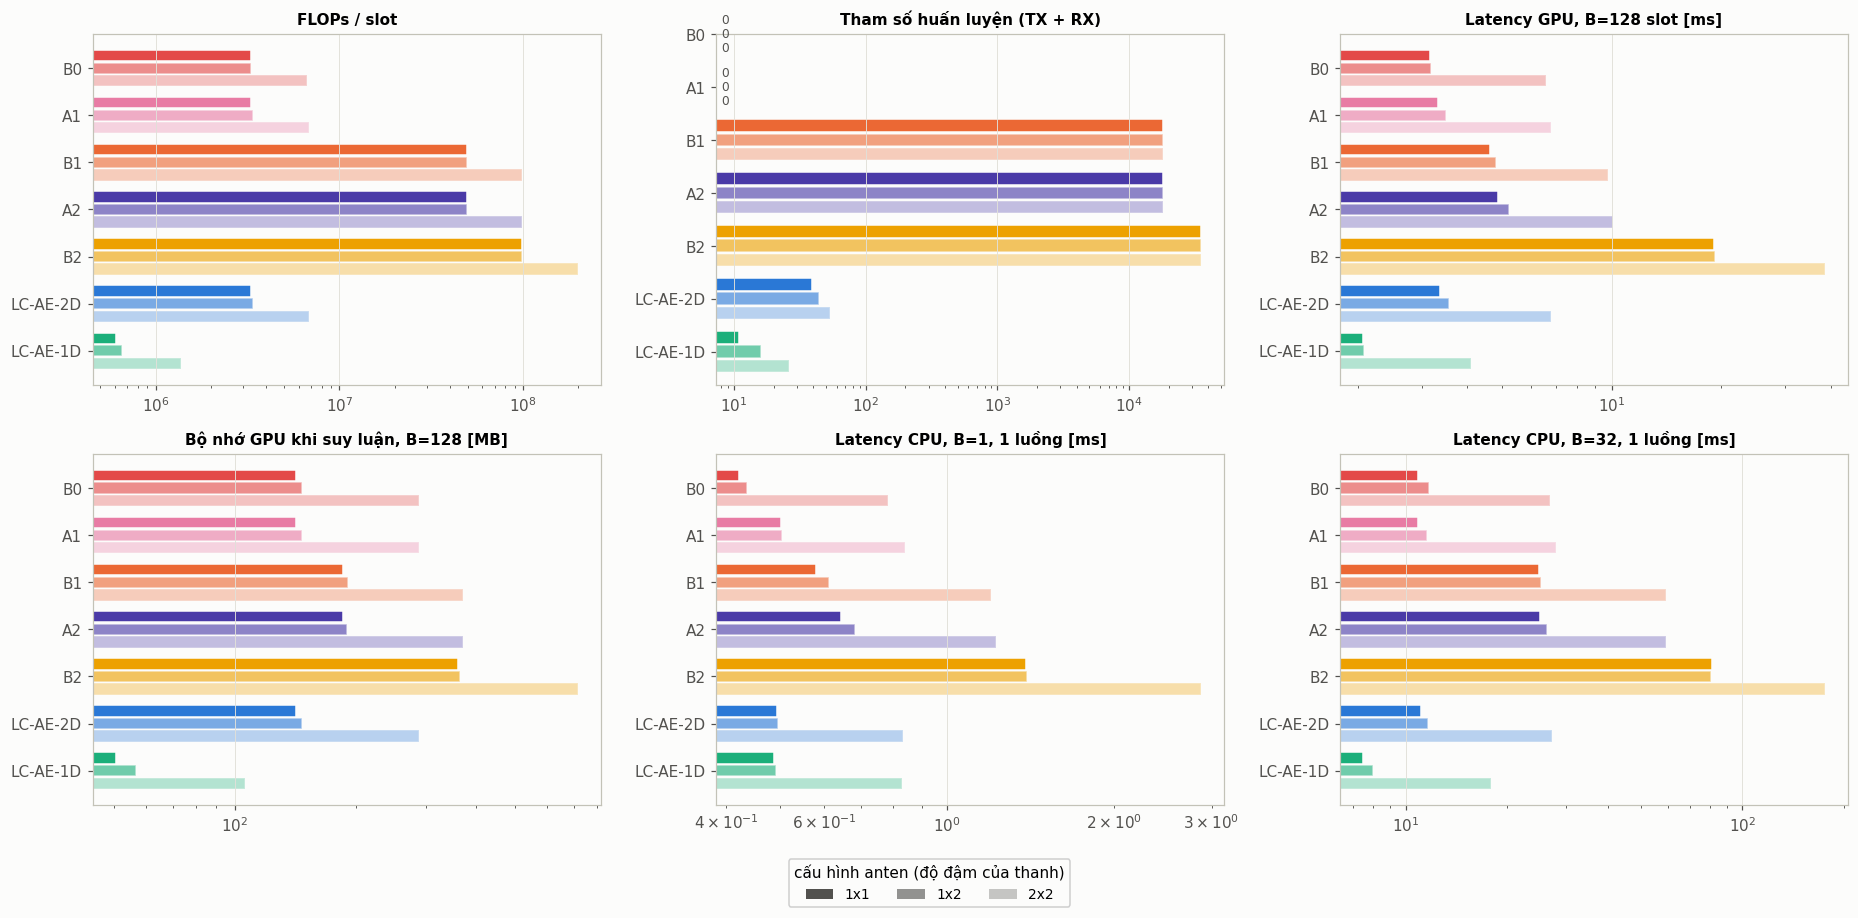

In [29]:
# One measure per panel (no dual axes); log scale; bars = systems (fixed colours), shade = antenna configuration.
from matplotlib.patches import Patch
metrics = [('flops_total', 'FLOPs / slot'), ('trainable_total', 'Tham số huấn luyện (TX + RX)'),
           ('gpu_ms_b128', 'Latency GPU, B=128 slot [ms]'), ('gpu_peak_mem_b128_MB', 'Bộ nhớ GPU khi suy luận, B=128 [MB]'),
           ('cpu_ms_b1_1thr', 'Latency CPU, B=1, 1 luồng [ms]'), ('cpu_ms_b32_1thr', 'Latency CPU, B=32, 1 luồng [ms]')]
sys_order = ['B0', 'A1', 'B1', 'A2', 'B2', 'LC2D', 'LC1D']
cfg_alpha = {c: a for c, a in zip(ANT_CONFIGS, [1.0, 0.62, 0.32])}
fig, axs = plt.subplots(2, 3, figsize=(17, 8.2))
for ax, (key, title) in zip(axs.flat, metrics):
    w = 0.8 / len(ANT_CONFIGS)
    for j, sk in enumerate(ANT_CONFIGS):
        ys = np.arange(len(sys_order)) + (j - (len(ANT_CONFIGS) - 1) / 2) * w
        vals = [COMPLEXITY.get((sk, k), {}).get(key) for k in sys_order]
        for y_, v_, k in zip(ys, vals, sys_order):
            if v_ is None or not np.isfinite(v_):
                continue
            if v_ <= 0:
                ax.text(0.01, y_, '0', va='center', ha='left', fontsize=8, color=INK2, transform=ax.get_yaxis_transform())
                continue
            ax.barh(y_, v_, height=w * 0.9, color=STYLE[k][1], alpha=cfg_alpha[sk], edgecolor='#fcfcfb', lw=1)
    ax.set_xscale('log'); ax.set_title(title, fontsize=10)
    ax.set_yticks(range(len(sys_order)), [STYLE[k][0].split(':')[0].split(' (')[0] for k in sys_order])
    ax.invert_yaxis(); ax.grid(axis='y', visible=False)
fig.legend(handles=[Patch(facecolor=INK2, alpha=cfg_alpha[c], label=c) for c in ANT_CONFIGS],
           title='cấu hình anten (độ đậm của thanh)', loc='lower center', ncol=len(ANT_CONFIGS), fontsize=9,
           bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig(fig_path('complexity'), dpi=150, bbox_inches='tight'); plt.show()

## 11. Trực quan: chòm sao đã học và đường học

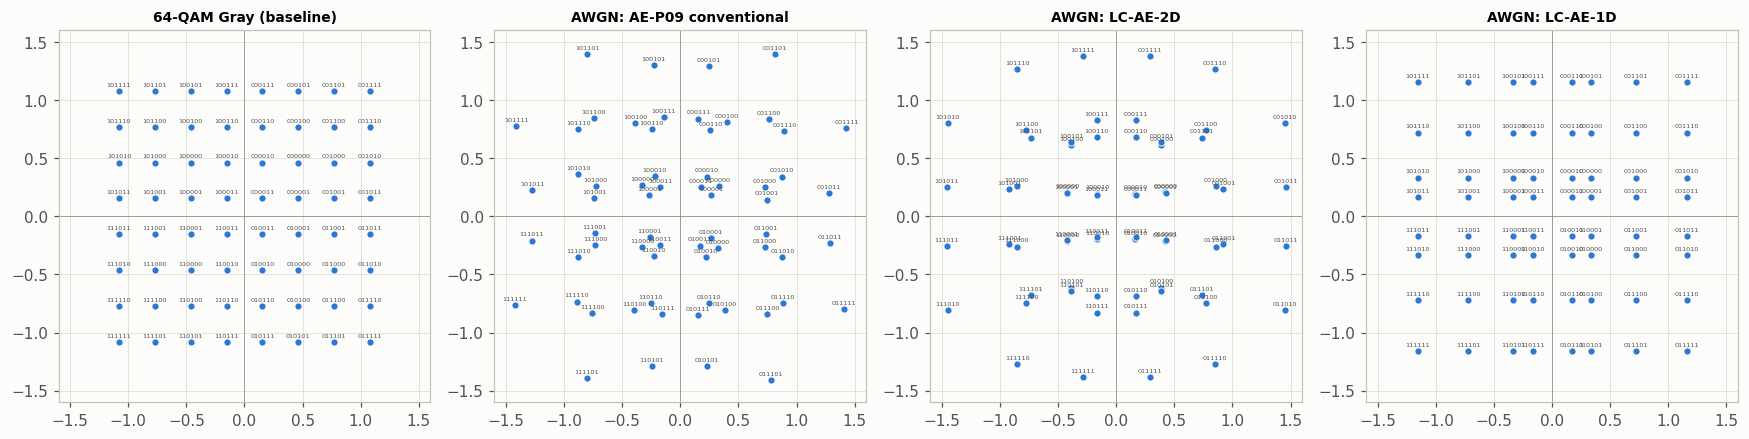

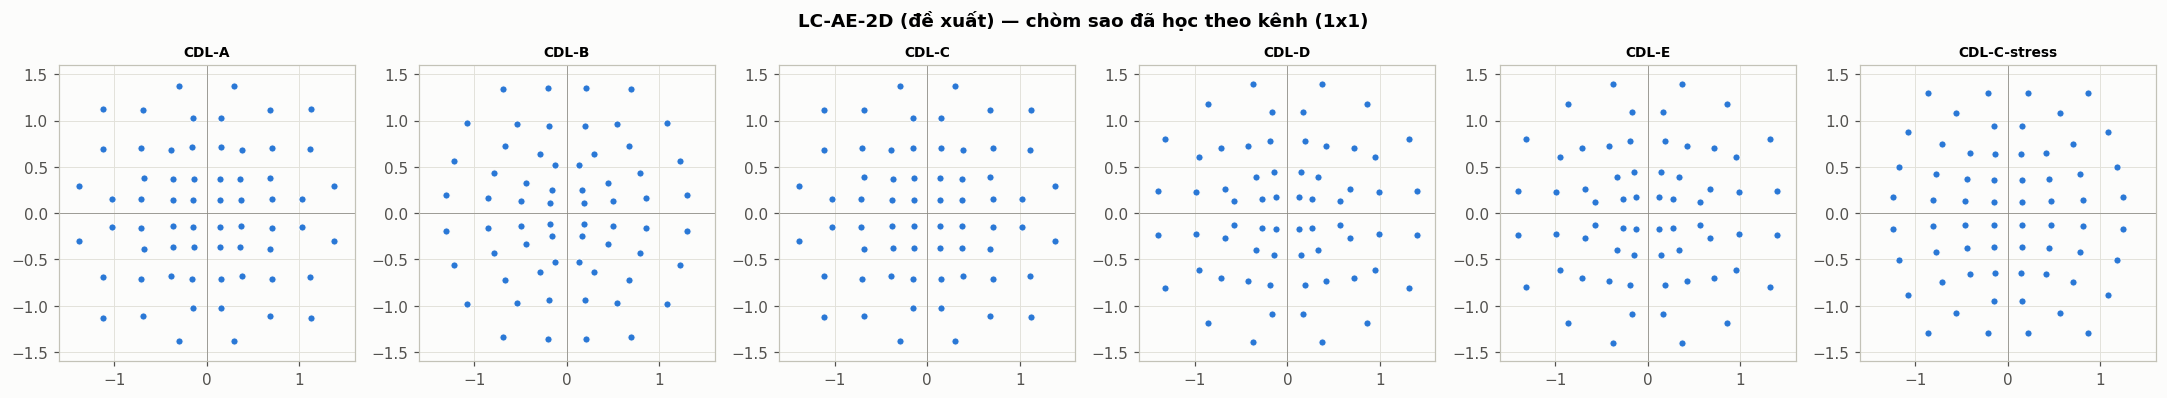

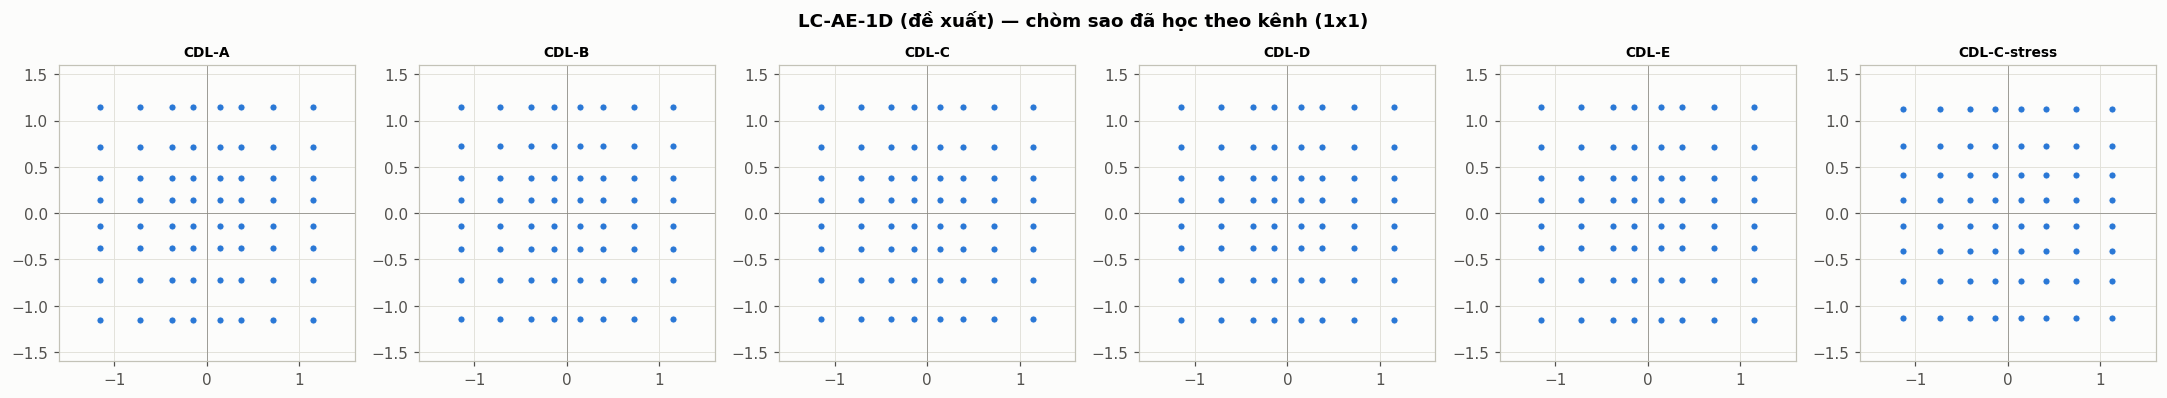

In [30]:
def draw_const(ax, pts, title, labels=True):
    pts = pts.detach().cpu().numpy()
    ax.scatter(pts.real, pts.imag, s=22, color=STYLE['LC2D'][1], edgecolor='#fcfcfb', lw=0.6, zorder=3)
    if labels:
        for i, p in enumerate(pts):
            ax.annotate(f'{i:06b}', (p.real, p.imag), fontsize=4.2, color=INK2, ha='center', va='bottom',
                        xytext=(0, 2.5), textcoords='offset points')
    ax.set_aspect('equal'); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.axhline(0, color=MUTED, lw=0.5); ax.axvline(0, color=MUTED, lw=0.5)
    ax.set_title(title, fontsize=9)


fig, axs = plt.subplots(1, 4, figsize=(16, 4.3))
draw_const(axs[0], _QAM, '64-QAM Gray (baseline)')
draw_const(axs[1], AWGN_LINKS['AE-conv'].tx.points(), 'AWGN: AE-P09 conventional')
draw_const(axs[2], AWGN_LINKS['LC2D'].tx.points(), 'AWGN: LC-AE-2D')
draw_const(axs[3], AWGN_LINKS['LC1D'].tx.points(), 'AWGN: LC-AE-1D')
fig.tight_layout(); fig.savefig(fig_path('constellations_awgn'), dpi=160); plt.show()

sk0 = ANT_CONFIGS[0]
for kind, cls in (('LC2D', SymGSConstellation), ('LC1D', NUC1DConstellation)):
    fig, axs = plt.subplots(1, len(CHANNEL_KEYS), figsize=(3.3 * len(CHANNEL_KEYS), 3.5), squeeze=False)
    for i, ck in enumerate(CHANNEL_KEYS):
        wp = OUT_DIR / 'weights' / f'claude_{sk0}_{ck}_{kind}.pt'
        if not wp.exists():
            axs[0][i].axis('off'); continue
        sd = torch.load(wp, map_location=device, weights_only=True)['state_dict']
        tx = cls().to(device)
        tx.load_state_dict({k_[3:]: v_ for k_, v_ in sd.items() if k_.startswith('tx.')})
        draw_const(axs[0][i], tx.points(), f'{ck}', labels=False)
    fig.suptitle(f'{STYLE[kind][0]} — chòm sao đã học theo kênh ({sk0})', fontweight='bold')
    fig.tight_layout(); fig.savefig(fig_path(f'constellations_{kind}_{sk0}'), dpi=150); plt.show()

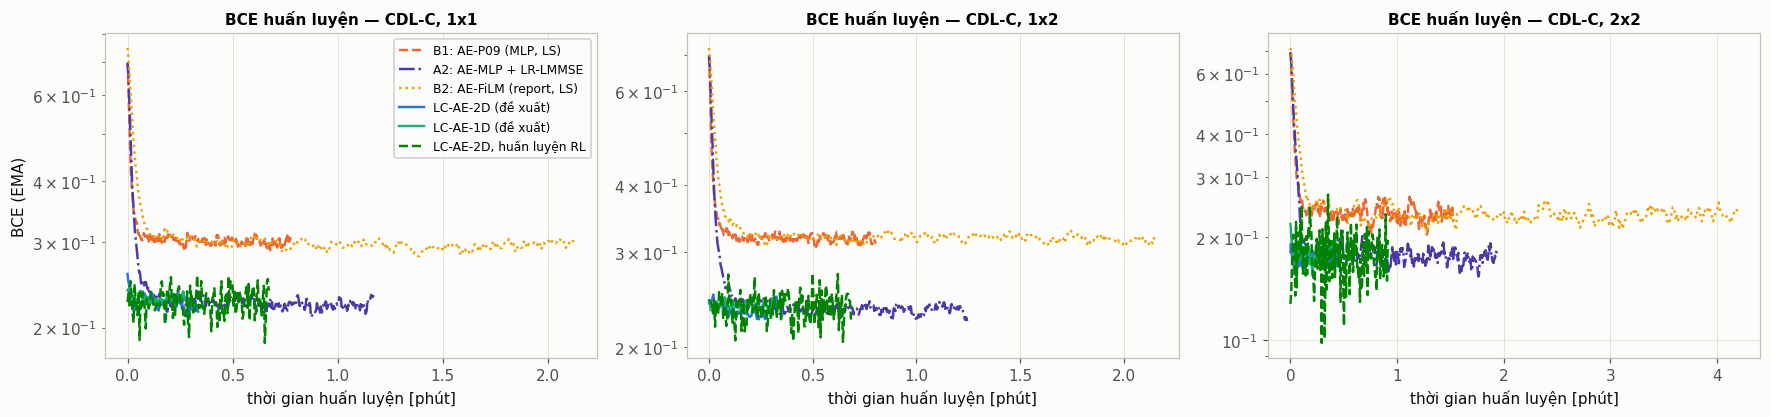

In [31]:
fig, axs = plt.subplots(1, len(ANT_CONFIGS), figsize=(5.4 * len(ANT_CONFIGS), 3.9), squeeze=False)
for i, sk in enumerate(ANT_CONFIGS):
    ax = axs[0][i]
    for k in ('B1', 'A2', 'B2', 'LC2D', 'LC1D', 'LC2D-RL'):
        tl = TRAIN_LOG.get((sk, 'CDL-C', k))
        if not tl:
            continue
        h_ = tl['hist']
        t_axis = np.array(h_['it']) * tl['info']['ms_per_iter'] / 1e3 / 60
        lab, col, ls, mk = STYLE[k]
        ax.plot(t_axis, h_['loss'], color=col, ls=ls, lw=1.6, label=lab)
    ax.set_xlabel('thời gian huấn luyện [phút]'); ax.set_title(f'BCE huấn luyện — CDL-C, {sk}', fontsize=10)
    ax.set_yscale('log')
    if i == 0:
        ax.set_ylabel('BCE (EMA)')
axs[0][0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(fig_path('training_curves'), dpi=150); plt.show()

## 12. Tổng kết

In [32]:
summary = {
    'hardware': HW,
    'awgn_thresholds': AWGN_TH.reset_index().to_dict(orient='records'),
    'ofdm_thresholds': TH.to_dict(orient='records'),
    'ablation_cdlc_steps': ABL_STEPS.reset_index().to_dict(orient='records'),
    'complexity': {f'{sk}|{k}': v for (sk, k), v in COMPLEXITY.items()},
    'ranks': rank_tab.to_dict(orient='records'),
    'calibration': {f'{sk}|{ck}': v for (sk, ck), v in CALIB.items()},
    'train': {f'{sk}|{ck}|{k}': v['info'] for (sk, ck, k), v in TRAIN_LOG.items()},
}
with open(OUT_DIR / 'claude_summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=1, ensure_ascii=False, default=float)
with open(OUT_DIR / 'claude_bler_all.pkl', 'wb') as f:
    pickle.dump({'ofdm': {f'{a}|{b}|{c}': v for (a, b, c), v in CURVES.items()}, 'awgn': AWGN_CURVES}, f)
log('=== notebook finished ===')
print('Saved:', sorted(p.name for p in OUT_DIR.glob('*.*')))

[2026-09-27 03:42:18] === notebook finished ===


Saved: ['claude_bler_all.pkl', 'claude_complexity.csv', 'claude_complexity.json', 'claude_summary.json', 'claude_thresholds.csv']


### 12.1 BLER: LC-AE thắng cả hai baseline trên mọi kênh và mọi cấu hình anten

Eb/N0 [dB] cần để đạt BLER $10^{-2}$ (nội suy log-tuyến tính, paired seeds). Δ > 0 nghĩa là LC-AE-2D cần ít Eb/N0 hơn.

| Cấu hình | Kênh | Perfect CSI | B0 (QAM+LS) | B1 (AE-P09) | **LC-AE-2D** | **LC-AE-1D** | Δ so với B0 | Δ so với B1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| SISO | CDL-A | 7.49 | 10.46 | 9.48 | **7.38** | **7.40** | +3.08 | +2.10 |
| SISO | CDL-B | 9.76 | 12.88 | 12.57 | **9.71** | **9.76** | +3.17 | +2.86 |
| SISO | CDL-C | 8.26 | 11.60 | 10.95 | **8.23** | **8.23** | +3.37 | +2.71 |
| SISO | CDL-D | 7.32 | 10.18 | 9.13 | **7.14** | **7.20** | +3.04 | +1.99 |
| SISO | CDL-E | 7.31 | 10.16 | 9.02 | **7.13** | **7.18** | +3.04 | +1.89 |
| SISO | CDL-C-stress | 9.76 | error floor | 13.35 | **9.74** | **9.76** | — | +3.61 |
| SIMO 1×2 | CDL-A | 4.19 | 7.33 | 6.15 | **4.08** | **4.09** | +3.25 | +2.07 |
| SIMO 1×2 | CDL-B | 5.27 | 8.40 | 7.60 | **5.13** | **5.19** | +3.27 | +2.47 |
| SIMO 1×2 | CDL-C | 4.28 | 7.39 | 6.32 | **4.12** | **4.15** | +3.27 | +2.19 |
| SIMO 1×2 | CDL-D | 4.32 | 7.41 | 6.27 | **4.13** | **4.20** | +3.28 | +2.14 |
| SIMO 1×2 | CDL-E | 4.28 | 7.43 | 6.27 | **4.18** | **4.19** | +3.25 | +2.10 |
| SIMO 1×2 | CDL-C-stress | 5.20 | error floor | 9.14 | **5.13** | **5.20** | — | +4.01 |
| MIMO 2×2 | CDL-A | 18.88 | 20.92 | 20.72 | **18.92** | **18.85** | +2.00 | +1.80 |
| MIMO 2×2 | CDL-B | 15.81 | 18.56 | 18.25 | **15.93** | **15.86** | +2.63 | +2.33 |
| MIMO 2×2 | CDL-C | 18.20 | 21.31 | 20.91 | **18.19** | **18.22** | +3.12 | +2.72 |
| MIMO 2×2 | CDL-D | 3.31 | 6.31 | 5.69 | **3.24** | **3.27** | +3.07 | +2.45 |
| MIMO 2×2 | CDL-E | 1.71 | 4.65 | 4.06 | **1.60** | **1.64** | +3.05 | +2.46 |
| MIMO 2×2 | CDL-C-stress | 16.06 | error floor | 18.95 | **16.10** | **16.13** | — | +2.84 |

**Nhận xét**

* **LC-AE-2D bám sát Perfect CSI trong cả 18 trường hợp** (chênh −0.19…+0.12 dB). Ở 15/18 trường hợp nó còn *vượt* Perfect CSI + 64-QAM, vì shaping bù lại phần nhỏ mất mát do ước lượng kênh.
* **Lợi ích so với B0 là +2.0…+3.4 dB, so với B1 là +1.8…+4.0 dB** tại $10^{-2}$. Tại $10^{-3}$ mức lợi tương đương hoặc lớn hơn: SISO/SIMO +3.1…+3.6 dB so với B0. B1 có **error floor** ở SISO CDL-A (~2.5·10⁻³) và CDL-C (~1.7·10⁻³), nên không bao giờ đạt $10^{-3}$.
* **LC-AE-1D chênh LC-AE-2D không quá ±0.07 dB** trên kênh fading, dù demapper rẻ hơn khoảng 6 lần (396 so với 2 346 FLOP/symbol). Trên AWGN khoảng cách này là 0.15–0.3 dB (mục 12.4).
* **MIMO 2×2 (CDL-A/B/C, stress):** đường BLER thoải, khoảng một thập phân mỗi 10 dB. Lý do là tách LMMSE 2 stream với 2 anten chỉ có diversity bậc 1, và kênh gần như phẳng trong slot (hạng 4–6). Vì vậy $10^{-3}$ nằm ngoài dải quét và tôi báo cáo thêm ngưỡng $3\cdot10^{-3}$: LC-AE-2D tốt hơn B0 lần lượt +3.5 / +3.1 / +2.7 dB (CDL-A/B/C). Với CDL-D/E (LOS, dual-pol), kênh gần chéo nên đường cong dốc như SISO.

### 12.2 Độ phức tạp: thấp hơn B1 ở mọi chỉ số thông lượng; B=1 trên GPU là ngoại lệ duy nhất

Toàn bộ chuỗi thu từ $y$ đến LLR, không tính LDPC. Kênh CDL-C, RTX A2000 và i9-13900. "graph" là latency đo bằng CUDA Graph (loại bỏ overhead Python và launch kernel).

| SISO 1×1 | Tham số train | FLOPs/slot | GPU B=128 eager / graph [ms] | GPU B=1 graph [ms] | GPU mem [MB] | CPU B=1, 1 luồng [ms] | CPU B=32, 1 luồng [ms] | CPU B=32, 24 luồng [ms] | Train [phút] |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| B0: QAM + LS + APP | 0 | 3.29 M | 3.17 / 2.87 | 0.114 | 142 | 0.42 | 10.9 | 6.3 | — |
| **B1: AE-P09** | 17 926 | 49.6 M | 4.63 / 4.50 | **0.097** | 186 | 0.58 | 24.9 | 7.7 | 0.78 |
| B2: AE-FiLM (report) | 35 334 | 99.3 M | 19.1 / 18.8 | 0.171 | 359 | 1.39 | 81.0 | 29.4 | 2.13 |
| **LC-AE-2D** | **39** | **3.32 M** (÷15) | **3.38 / 2.94** | 0.136 | **142** | **0.49** | **11.1** (÷2.2) | **6.5** | **0.34** |
| **LC-AE-1D** | **11** | **0.61 M** (÷82) | **2.07 / 1.60** (÷2.8) | 0.142 | **51** (÷3.6) | **0.49** | **7.5** (÷3.3) | **5.2** | **0.31** |

| MIMO 2×2 | Tham số train | FLOPs/slot | GPU B=128 eager / graph [ms] | GPU B=1 graph [ms] | GPU mem [MB] | CPU B=1, 1 luồng [ms] | CPU B=32, 1 luồng [ms] | CPU B=32, 24 luồng [ms] | Train [phút] |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| B0: QAM + LS + APP | 0 | 6.69 M | 6.57 / 6.35 | 0.180 | 288 | 0.78 | 26.9 | 16.4 | — |
| **B1: AE-P09** | 17 926 | 99.2 M | 9.73 / 9.63 | 0.193 | 370 | 1.20 | 59.1 | 27.3 | 1.53 |
| B2: AE-FiLM (report) | 35 334 | 199 M | 38.5 / 38.1 | 0.376 | 715 | 2.88 | 175.7 | 93.9 | 4.19 |
| **LC-AE-2D** | **54** | **6.81 M** (÷15) | **6.82 / 6.44** | 0.204 | **288** | **0.83** | **27.2** (÷2.2) | **16.6** | **0.47** |
| **LC-AE-1D** | **26** | **1.38 M** (÷72) | **4.10 / 3.76** (÷2.6) | **0.181** | **106** (÷3.5) | **0.83** | **18.0** (÷3.3) | **10.6** | **0.41** |

(÷x = số lần thấp hơn B1. Kết quả SIMO 1×2 gần như trùng SISO, xem bảng đầy đủ ở mục 10.)

* **FLOPs:** LC-AE-2D thấp hơn B1 khoảng 15×, LC-AE-1D thấp hơn 72–82×. LC-AE-1D còn thấp hơn cả B0 5.4× (SISO).
* **Thông lượng GPU (B=128) và CPU (B=32):** LC-AE-2D nhanh hơn B1 1.2–2.2×, LC-AE-1D nhanh hơn 1.5–3.3× (lợi nhất khi CPU chạy 1 luồng). Bộ nhớ GPU khi suy luận của LC-AE-1D chỉ bằng khoảng 1/3.5.
* **CPU với B=1:** LC-AE nhanh hơn B1 (0.49 so với 0.58 ms ở SISO; 0.83 so với 1.20 ms ở MIMO).
* **GPU với B=1 là ngoại lệ:** B1 nhỉnh hơn (0.097 so với 0.136 ms ở SISO, đã dùng CUDA Graph). Ở kích thước này latency bị chi phối bởi *số kernel*: ước tính MLP chỉ cần khoảng 25 kernel, còn LR-LMMSE + APP cần khoảng 50. Ở MIMO, LC-AE-1D lại nhanh hơn (0.181 so với 0.193 ms).
* **Huấn luyện:** LC-AE cần 3 000 vòng thay vì 10 000, tổng thời gian ít hơn 2.3–3.3×, bộ nhớ huấn luyện ít hơn 1.7–3.6×, và số tham số ít hơn 330–1 600×.
* **So với chi phí LDPC:** toàn bộ bộ thu chỉ chiếm ~1.4 % so với decoder (233 ms cho 128 slot SISO). Bản B0 viết lại cũng nhanh hơn chuỗi khối Sionna gốc 9× (3.2 so với 28 ms) mà cho kết quả trùng khớp (mục 4.4).
* **B2 (FiLM, theo `suggestion_report.md`):** gấp đôi FLOPs và chậm hơn B1 4×, nhưng BLER chỉ ngang B1 (±0.25 dB). Tăng độ phức tạp của demapper không giải quyết được nút thắt thật là ước lượng kênh.

### 12.3 Lợi ích đến từ đâu? (ablation trên CDL-C, BLER $10^{-2}$)

| Bước | SISO | SIMO 1×2 | MIMO 2×2 |
|---|---:|---:|---:|
| **Ước lượng kênh**: B0 → A1 (LS-nn → LR-LMMSE, vẫn QAM) | **+3.16** | **+3.05** | **+3.01** |
| **Shaping + hiệu chỉnh LLR**: A1 → LC-AE-2D | +0.20 | +0.21 | +0.11 |
| Demapper MLP khi dùng cùng TX + CE: A2-APP → A2 | −0.13 | −0.03 | −0.02 |
| Hình học Free-64 so với SymGS-2D (cùng APP): LC-AE-2D → A2-APP | +0.07 | +0.21 | −0.01 |
| Huấn luyện RL (không cần đạo hàm kênh) so với conventional | +0.04 | +0.07 | −0.05 |
| Khoảng cách LC-AE-2D so với Perfect CSI + QAM | −0.03 | −0.15 | −0.01 |

1. **Khoảng 93–96 % lợi ích đến từ ước lượng kênh.** LS nearest-neighbour dùng *một* pilot nhiễu cho mỗi RE. Trong khi đó kênh CDL ở DS 100 ns chỉ có hạng 4–10 trên lưới 14×116, nên bộ lọc Wiener trong subspace đó lấy trung bình được hàng trăm pilot. NMSE giảm từ −16 dB xuống −34 dB (mục 4.4), với tối đa 0.12 MFLOP/slot.
2. **Phần autoencoder (shaping) đóng góp +0.1…+0.2 dB** trên kênh fading, so với +0.4 dB trên AWGN. Phần này gần như miễn phí khi suy luận vì chòm sao chỉ là bảng tra.
3. **MLP không cần thiết:** với cùng chòm sao và cùng bộ ước lượng kênh, APP chính xác tốt bằng hoặc hơn MLP 17.8k tham số (A2-APP so với A2). Ưu thế nhỏ của A2 ở SIMO (+0.18 dB so với LC-AE-2D) đến từ **hình học chòm sao tự do** (128 tham số, 10 000 vòng), không phải từ MLP.
4. **Huấn luyện RL** theo thuật toán P09 hội tụ tới cùng chất lượng (±0.07 dB). Vậy LC-AE vẫn dùng được khi kênh không khả vi.

### 12.4 AWGN (tái hiện P09)

| Hệ thống | Tham số | $10^{-2}$ | $10^{-3}$ | $10^{-4}$ |
|---|---:|---:|---:|---:|
| QAM + APP (baseline P09) | 0 | 6.49 | 6.89 | 7.37 |
| AE-P09 conventional (weights gốc) | 17 926 | 6.09 | 6.54 | 6.96 |
| AE-P09 RL (weights gốc) | 17 926 | 6.06 | 6.48 | 6.91 |
| **LC-AE-2D** | **34** | **6.07** | **6.48** | **6.87** |
| LC-AE-1D | 6 | 6.22 | 6.67 | 7.20 |

* Đường BLER tái hiện khớp với đường P09 đã lưu.
* **LC-AE-2D bằng hoặc tốt hơn AE-P09**, trong khi chỉ có 34 tham số, huấn luyện 11 giây, và demapper tốn 2.3 kFLOP/symbol so với 35.6 kFLOP (÷15).
* LC-AE-1D tốt hơn QAM 0.2–0.3 dB nhưng kém AE-P09 0.15–0.3 dB. Đây là cái giá của ràng buộc tích I/Q, và đúng như rủi ro đã nêu trong plan.

### 12.5 Hạn chế (báo cáo trung thực)

* **Lệch thống kê kênh là điểm yếu lớn nhất.** LC-AE huấn luyện trên CDL-C (hạng 4) *hỏng hoàn toàn* trên CDL-C-stress (DS 300 ns, 30 m/s): BLER khoảng 0.7–0.9 ở mọi SNR (mục 9.2).
  * Nguyên nhân: subspace quá hẹp để biểu diễn kênh mới, trong khi phương sai sai số mô hình $\varepsilon$ học trên CDL-C lại rất nhỏ, nên LLR sai một cách tự tin.
  * B1 huấn luyện trên CDL-C cũng suy giảm (floor khoảng $2\cdot10^{-2}$ ở SISO; ở SIMO BLER tăng trở lại khi SNR cao) nhưng ít thảm họa hơn.
  * Mô hình chuyên biệt cho stress thì vẫn chạm Perfect CSI. Như vậy LC-AE **cần thống kê kênh đúng**: khoảng 16k realization, ước lượng mất vài giây, hoặc lấy từ dữ liệu đo.
* **GPU với B=1:** B1 nhanh hơn khoảng 0.04 ms do ít kernel hơn (xem 12.2).
* **Đo độ phức tạp** thực hiện trên PyTorch eager/CUDA Graph, không dùng kernel hợp nhất (`torch.compile` không dùng được trên Windows). Số FLOPs được đếm giải tích theo đúng phép toán đã cài đặt.
* **Thay đổi giao thức so với plan:**
  * Codeword n = 1392 (6 codeword/stream/slot) thay vì n = 8352, vì decode n = 8352 tốn 3.1 ms/codeword.
  * Quy tắc dừng: sau khi phát hiện một số đường bị dừng sớm ở "vai" BLER, tôi siết lại quy tắc (floor khi BLER giảm dưới 1.43× qua 4 bước; dưới 1.25× với đường thoải) và **tính lại mọi đường bị ảnh hưởng**. Paired seeds bảo đảm các điểm chung trùng khớp.
  * MIMO với waterfall thoải: dừng ở $3\cdot10^{-3}$.

### 12.6 Hướng phát triển tiếp theo

1. **LC-AE-Robust**, để xử lý lệch thống kê kênh:
   * dùng thống kê hỗn hợp (DS 30–300 ns, 0–30 m/s) với hạng lớn hơn, như LR-NRx-Robust ở P05;
   * thêm ước lượng $\varepsilon$ *trực tuyến* từ phần dư pilot $\|z-\Phi\hat c\|^2$. Việc này tốn khoảng $O(R\cdot P)$ FLOP và giúp LLR tự "mềm" đi khi kênh lệch.
2. **Chòm sao Free-64 + APP.** Tham số TX không tốn gì khi suy luận, nên bỏ ràng buộc đối xứng và huấn luyện 10 000 vòng có thể lấy thêm khoảng 0.2 dB ở SIMO (như A2-APP cho thấy).
3. **MIMO:** nút thắt là bậc diversity của LMMSE chứ không phải ước lượng kênh. Có thể kết hợp LC-AE với bộ tách SIC/K-best hoặc với tiền mã hóa/xoay chòm sao học end-to-end.
4. **Kernel hợp nhất** (CUDA/Triton) cho APP-2D và LR-LMMSE, để loại bỏ bất lợi ở B=1 trên GPU.